# [이론] 분위수와 포함률 — 80% 구간을 그대로 써도 되는가

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 왜 80% 구간이 필요한가

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 딥러닝 시계열</div>
<h1 style="color:#000000;margin:10px 0">분위수와 포함률 — 80% 구간을 그대로 써도 되는가</h1>
<div style="font-size:1.05em;color:#656565">Chronos-2 의 80% 구간은 서울 지하철 100개 역에서 포함률이 몇 % 였고, 인력 계획에 어떻게 쓰는가</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)는 선택입니다.

### 핵심 질문: 80% 구간을 인력 계획에 그대로 써도 되는가 [필수]

서울 지하철 100개 역의 다음 주 7일 승차 인원을 역마다 예측합니다. 역 운영팀은 이 예측으로 역마다 인력을 정합니다.

예측에는 공휴일 열을 입력한 Chronos-2 를 씁니다. 공변량을 배울 때 **Chronos-2 + 공휴일**이라고 부른 예측입니다.

<img src="https://en.wikipedia.org/wiki/Special:FilePath/Seoul_subway_linemap_ko.svg" alt="서울 지하철 노선도" width="320" height="364"/>
<p align="center"><em>▲ 서울 지하철 노선도. 이 과정에서 예측하는 역은 지금까지와 같은 100개 역이고, 노선 13개에 있다 (출처: Wikimedia Commons, Seoul subway linemap ko.svg)</em></p>

지금까지는 Chronos-2 의 예측 표에서 `"0.5"` 열 하나를 점 예측으로 써서 채점했습니다.

그런데 점 예측만큼만 인력을 준비하면, 실제 승차 인원이 그보다 많은 날에는 인력이 모자랍니다. 점 예측 하나로는 그런 날에 얼마나 더 준비해야 하는지 알 수 없습니다.

그래서 인력 계획에는 값 하나보다 범위가 필요합니다. 같은 예측 표에서 이 범위로 쓰는 것이 **80% 구간**입니다.

하지만 이름의 80% 는 모델이 계산한 확률입니다. 실제 승차 인원이 그만큼 구간 안에 있었는지는 실제값이 나온 뒤에 확인해야 알 수 있습니다.

따라서 이 수업의 핵심 질문은 하나입니다.

> 공휴일 열을 입력한 Chronos-2 의 80% 구간을 다음 주 역별 인력 계획에 그대로 써도 되는가?

결론부터 말하면 세 가지입니다.

- 공휴일이 없는 주에는 실제 승차 인원이 구간 안에 있던 날이 80% 가까이였습니다.
- 평일 공휴일이 있는 주에는 공휴일 열을 입력하기 전보다 구간이 길었는데도 그 비율이 80% 에 못 미쳤습니다.
- 따라서 구간은 그 주에 해당하는 비율과 함께 전달하고, 평일 공휴일 당일의 인력은 구간으로 정하지 않습니다.

### 80% 구간은 예측 표의 어느 열인가 [필수]

80% 구간은 예측 표의 `"0.1"` 열과 `"0.9"` 열 사이입니다.

Chronos-2 의 예측 표에는 한 행에 분위수 열이 `"0.1"` 부터 `"0.9"` 까지 아홉 개 있습니다.

먼저 작은 예시로 설명합니다. 가게 한 곳의 다음 수요일 손님 수를 예측한 행이 아래와 같다고 하겠습니다.

| 예측 표의 열 | `"0.1"` | `"0.2"` | `"0.3"` | `"0.4"` | `"0.5"` | `"0.6"` | `"0.7"` | `"0.8"` | `"0.9"` |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 다음 수요일 손님 수(명) | **80** | 85 | 90 | 95 | **100** | 105 | 110 | 115 | **120** |
| 쓰임 | 80% 구간의 아래 끝 | | | | 점 예측 | | | | 80% 구간의 위 끝 |

`"0.5"` 열의 100명이 지금까지 쓴 점 예측이고, 양 끝 두 열의 80명과 120명이 80% 구간의 두 끝입니다.

두 열은 아홉 열 가운데 맨 바깥이라, 80% 구간은 이 표에서 만들 수 있는 가장 넓은 구간입니다.

즉, 80% 구간의 두 끝은 **이미 얻은 예측 표에 있는 두 열**이라, 예측을 다시 할 필요가 없습니다.

<div class="lms-summary">

**정리**

점 예측만으로는 실제 승차 인원이 더 많은 날의 인력을 정할 수 없어, 인력 계획에는 범위가 필요합니다. 예측 표의 `"0.1"` 열과 `"0.9"` 열 사이가 그 범위인 80% 구간입니다.

80% 는 모델이 계산한 확률이므로, 구간을 그대로 쓸지는 실제값으로 확인한 뒤에 정합니다.

</div>

## 1. 분위수와 80% 구간

예측 표의 분위수 열에 있는 값은 무엇을 뜻하고, 80% 구간은 무엇의 범위일까요?

### 분위수란 무엇인가 [필수]

**분위수(quantile)** 는 실제가 그 값 이하일 확률로 정한 값입니다.

가게의 지난 수요일 10번으로 확인합니다. 아래 표는 그 손님 수를 작은 값부터 나열한 것이고, Chronos-2 의 출력을 배울 때 본 표와 같습니다.

| 손님 수(명) | 80 | 85 | 90 | 95 | 100 | 105 | 110 | 115 | 120 | 150 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 그 값 이하인 날(10번 가운데) | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
| 분위수 | 0.1 | 0.2 | 0.3 | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 | 1.0 |

80명 이하인 날은 10번 가운데 1번입니다. 그래서 80명이 0.1 분위수입니다.

같은 방법으로 100명이 0.5 분위수, 120명이 0.9 분위수입니다.

> 0.9 분위수는 실제가 그 값 이하일 확률이 90% 인 값입니다.

분위수의 뜻은 그 값만큼 준비했을 때 모자라는 횟수로 확인할 수 있습니다. **준비량**은 그날 손님 몇 명을 받을 만큼 준비할지 정한 값입니다. 100명을 받을 만큼이면 100명분입니다.

| 준비량 | 지난 수요일 10번 가운데 손님이 더 많았던 날 |
|---|---|
| 0.5 분위수 100명분 | 5번(105 · 110 · 115 · 120 · 150명) |
| 0.9 분위수 120명분 | 1번(150명) |

즉, 0.5 분위수만큼 준비하면 두 번에 한 번, 0.9 분위수만큼 준비하면 **열 번에 한 번**은 모자랍니다. 어느 분위수에 맞출지는 임계비율(모자랄 때와 남을 때의 비용으로 정하는 분위수)을 배울 때 정합니다.

여기서 흔한 오해는 0.9 분위수를 올 수 있는 가장 많은 손님 수로 보는 것입니다. 하지만 지난 10번에도 120명보다 많은 150명인 날이 있었습니다.

한편 지난 수요일 10번 표의 분위수는 지난 손님 수로 구한 값이고, 예측 표의 분위수 열은 모델이 계산한 값입니다. 가게 예시에서는 둘이 같다고 가정하고 80명 · 100명 · 120명으로 계산합니다.

<details class="lms-extra"><summary>더 깊이 — 강남역 수요일 52번에서 구한 분위수</summary>

가게의 지난 10번 대신 강남역의 지난 수요일 52번(2025-06-25～2026-06-17)으로 같은 계산을 합니다. 아래 표의 수는 예측이 아니고, 이 52번의 실제 승차 인원으로 구한 값입니다.

| 매주 준비하는 값 | 52번에서 구한 값 | 인력이 모자란 수요일 |
|---|---:|---:|
| 26번째 값(0.5 분위수) | 90,582명 | 26번 |
| 47번째 값(0.9 분위수) | 93,403명 | 5번 |

0.9 분위수만큼 매주 준비했다면 52번 가운데 5번 모자랐습니다. 가게 예시처럼 열 번에 한 번 정도입니다.

승차 인원을 작은 값부터 나열하면, 0.9 분위수는 그 값 이하인 비율이 처음으로 90% 에 닿는 값입니다. 52번의 90% 는 52 × 0.9 = 46.8번이라, 46번째 값과 47번째 값을 확인합니다.

- 46번째 값 93,035명: 이하인 수요일이 46번이라 46 ÷ 52 = 88.5% 로 90% 에 못 미칩니다
- 47번째 값 93,403명: 이하인 수요일이 47번이라 47 ÷ 52 = 90.4% 로 처음 90% 를 넘습니다

그래서 0.9 분위수는 47번째 값입니다. 같은 규칙으로 0.5 분위수는 52 × 0.5 = 26 이라 26번째 값 90,582명입니다.

넘파이의 `np.quantile` 에 `method="inverted_cdf"` 를 지정하면 이 규칙으로 계산합니다. 지정하지 않으면 이웃한 두 값 사이를 보간해 다른 값이 나옵니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Normal_Distribution_CDF.svg" alt="정규분포 네 개의 누적분포 곡선" width="560" height="358"/>
<p align="center"><em>▲ 정규분포 네 개의 누적분포 곡선. 세로축은 그 값 이하일 확률이다. 세로축 0.9 에서 가로로 그은 선이 곡선과 만나는 가로축 값이 그 분포의 0.9 분위수다 (출처: Wikimedia Commons, Normal Distribution CDF.svg)</em></p>

| 그림의 글자 | 뜻 |
|---|---|
| $x$ | 가로축. 값이다 |
| $\Phi_{\mu,\sigma^2}(x)$ | 세로축. 값이 $x$ 이하일 확률이다 |

범례의 네 항목은 평균 $\mu$ 와 분산 $\sigma^2$ 가 다른 분포 넷입니다.

강남역 수요일 52번으로 이런 곡선을 그리면, 세로축 0.9 에 처음 닿는 가로축 값이 93,403명입니다.

</details>

### 80% 구간이란 무엇인가 [필수]

80% 구간은 0.1 분위수와 0.9 분위수 사이의 범위입니다.

가게의 지난 10번에서 80명 이하인 날은 1번이고, 120명 이하인 날은 9번입니다.

그래서 80명보다 많고 120명 이하인 날은 9 − 1 = 8번입니다.

비율로는 0.9 − 0.1 = 0.8, 곧 80% 입니다.

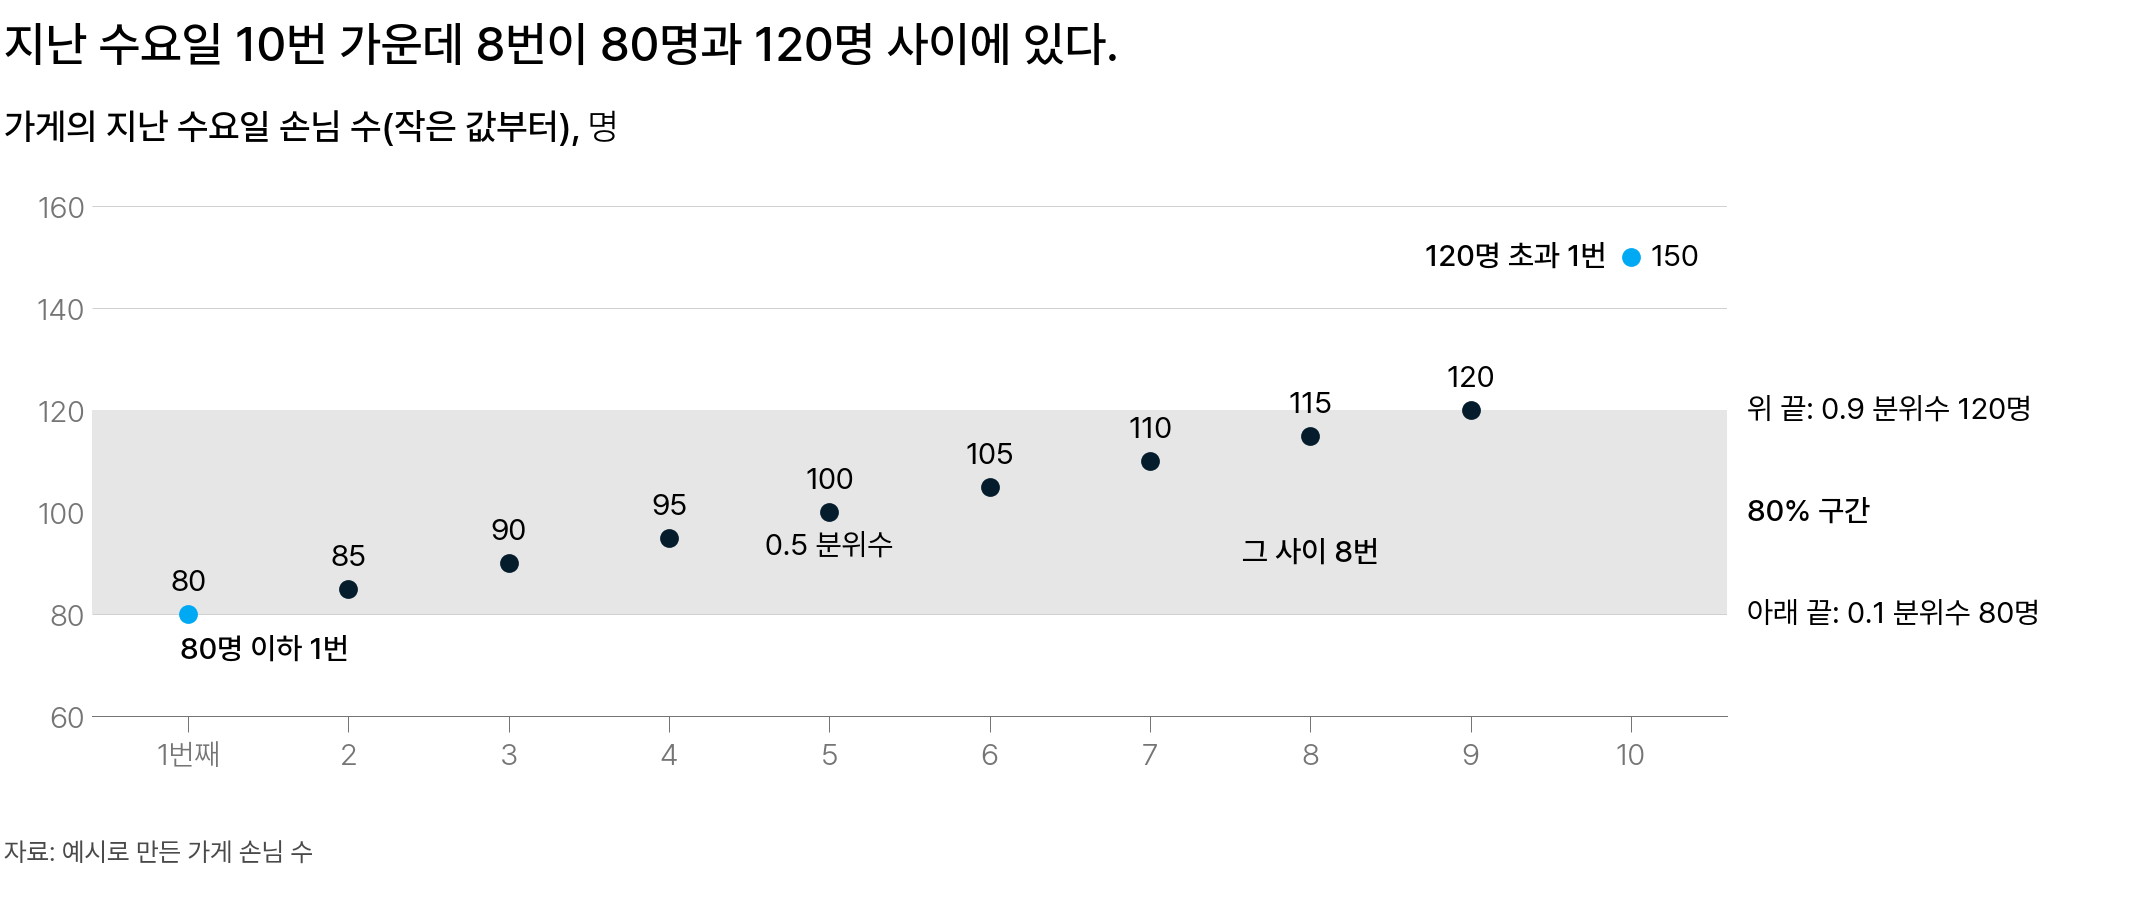

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 회색으로 칠한 80～120명이 80% 구간이고, 손님이 가장 많았던 날의 150명은 위 끝 120명보다 많다</em></p>

80% 구간의 정식 이름은 **80% 예측구간(80% prediction interval)** 입니다. 가게 예시에서는 80명이 **아래 끝**, 120명이 **위 끝**입니다.

여기서 80% 는 이 구간이 실제값을 포함하도록 정한 목표 비율입니다. 이 목표 비율을 **명목 포함률(nominal coverage)** 이라고 하고, 아래에서는 「명목 80%」로 줄여 씁니다.

예측 표의 80% 구간에서는 명목 80% 가 모델이 계산한 확률입니다. 80% 의 80 이 아래 끝 80명과 같은 것은 우연입니다.

> 80% 구간은 아래 끝인 0.1 분위수와 위 끝인 0.9 분위수 사이이고, 다음 하루의 값 하나가 있을 범위입니다.

두 끝을 더 안쪽 분위수로 바꾸면 구간이 짧아지고 명목 포함률도 낮아집니다.

| 두 끝 | 구간 | 명목 포함률 |
|---|---|---:|
| 0.3 분위수와 0.7 분위수 | 90～110명 | 40% |
| 0.2 분위수와 0.8 분위수 | 85～115명 | 60% |
| 0.1 분위수와 0.9 분위수 | 80～120명 | 80% |

명목 포함률은 위 끝 분위수에서 아래 끝 분위수를 뺀 값입니다. 첫 행은 0.7 − 0.3 = 0.4 입니다.

<details class="lms-extra"><summary>자세히 — 분위수와 80% 구간의 식</summary>

식으로 나타내기 전에, 분위수를 사람 100명의 그림으로 먼저 확인합니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Bell_Curve_Showing_100_Faces_to_Illustrate_Percentile_Rank.png" alt="종 모양 분포 안에 사람 100명을 점으로 찍은 그림" width="640" height="272"/>
<p align="center"><em>▲ 종 모양 분포 안에 사람 100명을 얼굴 점으로 찍은 그림. 가로축 값이 작은 쪽부터 세어 90번째 사람까지 오면 그 값이 0.9 분위수다 (출처: Wikimedia Commons, Bell Curve Showing 100 Faces to Illustrate Percentile Rank.png)</em></p>

분위수의 확률을 $\tau$ 라 하면, $\tau$ 분위수는 다음 식을 만족하는 값입니다.

$$
P(y \le q_{\tau}) = \tau
$$

- $y$: 그날 실제 손님 수(명)
- $q_{\tau}$: $\tau$ 분위수, 곧 예측 표에서 이름이 $\tau$ 인 열의 값(명)
- $\tau$: 분위수의 확률(0.1, 0.2, …, 0.9 가운데 하나)

가게 예시에서 $\tau = 0.9$ 이면 $q_{0.9}$ 는 120명입니다.

두 끝 사이가 80% 구간이므로, 실제가 두 끝 사이에 있을 확률을 구합니다.

위 끝 이하일 확률에서 아래 끝 이하일 확률을 빼고, 두 확률에 0.9 와 0.1 을 대입해 정리합니다.

$$
\begin{aligned}
P(q_{0.1} < y \le q_{0.9}) &= P(y \le q_{0.9}) - P(y \le q_{0.1}) \\
&= 0.9 - 0.1 \\
&= 0.8
\end{aligned}
$$

식의 확률은 모델이 계산한 값입니다.

지하철 승차 인원처럼 수가 큰 자료에서는 실제가 끝과 꼭 같은 날이 드뭅니다. 그래서 아래 끝과 같은 날을 구간 안으로 계산해도 결과가 같습니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 80% 구간과 95% 구간을 함께 그린 그림 읽기</summary>

<img src="https://otexts.com/fpp3/arima_files/figure-html/fig-usemployment7-1.png" alt="미국 여가·숙박업 고용자 수 예측의 80%·95% 구간" width="640" height="320"/>
<p align="center"><em>▲ 미국 여가·숙박업 고용자 수의 예측. 짙게 칠한 범위가 80% 구간, 옅게 칠한 범위가 95% 구간이다. 명목 포함률이 더 높은 95% 구간의 두 끝이 80% 구간보다 바깥에 있다 (출처: Hyndman &amp; Athanasopoulos, Forecasting: Principles and Practice 3rd ed.)</em></p>

시계열 예측 교재 Forecasting: Principles and Practice 에 실린 예측 그림입니다. 자료와 모델은 이 과정과 다릅니다. 명목 포함률이 다른 두 구간을 한 그림에서 비교하려고 실었습니다.

| 그림의 글자 | 뜻 |
|---|---|
| US employment: leisure and hospitality | 미국 여가·숙박업의 고용자 수 |
| Month | 가로축. 달마다 값이 하나다 |
| Number of people (millions) | 세로축. 고용자 수이고 단위는 백만 명이다 |
| level 80% | 짙게 칠한 범위. 80% 구간이다 |
| level 95% | 옅게 칠한 범위. 95% 구간이다 |

왼쪽의 검은 선이 과거의 실제값입니다.

오른쪽의 파란 선이 점 예측이고, 그 위아래로 칠한 두 범위가 예측구간입니다.

짙은 범위는 달마다 옅은 범위 안에 있습니다.

가게 예시에 적용하면 80% 구간이 80～120명일 때, 95% 구간의 두 끝은 그보다 바깥에 있습니다.

흔한 오해는 95% 구간이 더 좋은 구간이라는 것입니다. 95% 구간은 명목 포함률이 높아 더 길 뿐입니다.

이 과정의 예측 표에는 0.1 열부터 0.9 열까지만 있어, 95% 구간은 만들 수 없습니다.

</details>

**80% 구간은 평균이 있을 범위일까요?** 80% 구간은 다음 수요일 하루의 손님 수가 있을 범위입니다. 평균이 있을 범위는 시계열 과목에서 배운 **신뢰구간(confidence interval)** 이고, 예측구간과 다른 구간입니다.

| 구분 | 예측구간 | 신뢰구간 |
|---|---|---|
| 범위의 대상 | 다음 수요일 하루의 손님 수 | 수요일 평균 손님 수 |
| 가게 예시 | 80～120명 | 평균 105명 앞뒤의 더 좁은 범위 |
| 쓸 때 | 그날 오는 손님 수에 준비량을 맞출 때 | 평균이 달라졌는지 확인할 때 |

지난 10번의 손님 수를 모두 더하면 1,050명이라, 평균은 1,050 ÷ 10 = 105명입니다.

평균은 여러 날을 모아 구한 값이라, 하루의 값만큼 크게 달라지지 않습니다.

그런데 하루하루의 손님 수는 80명에서 150명까지 달랐습니다. 105명 앞뒤의 좁은 범위로는 그날 올 손님 수를 알 수 없습니다.

준비량은 그날 실제로 오는 손님 수에 맞춥니다. 따라서 준비량을 정할 때는 **예측구간**을 씁니다.

> **[문제] Chronos-2 + 공휴일이 낸 강남역 2026-06-26(금)의 0.9 분위수 열은 99,793명입니다. 이 값의 뜻으로 맞는 것은?**
>
> 1. 실제 승차가 99,793명 이하일 확률이 90% 다
> 2. 실제 승차가 99,793명을 넘을 확률이 90% 다
> 3. 이날 올 수 있는 가장 많은 승차다

<div class="lms-summary">

**정리**

분위수는 실제가 그 값 이하일 확률로 정한 값이고, 0.5 분위수가 점 예측입니다. 80% 구간의 두 끝은 0.1 분위수와 0.9 분위수이며, 이 구간은 다음 하루의 값 하나가 있을 범위입니다.

**할 일**

- `predict_df` 로 얻은 예측 표 `fc` 에서 `fc["0.1"]` 과 `fc["0.9"]` 두 열을 구간의 두 끝으로 씁니다

명목 80% 는 목표 비율입니다. 실제로 그만큼 포함하는지는 「2. 포함률과 구간 길이」에서 확인합니다.

</div>

> **[문제] 80% 구간은 다음 주 하루 평균 승차가 있을 범위다.**
>
> 1. O (맞다)
> 2. X (틀리다)

## 2. 포함률과 구간 길이

이 80% 구간이 실제로 80% 를 포함하는지는 어떻게 확인할까요?

### 포함률이란 무엇인가 [필수]

가게의 80% 구간을 80～120명으로 정했습니다.

그런데 이 구간이 맞는지는 지난 10번으로 확인할 수 없습니다. 지난 10번에서는 8번이 안에 있도록 두 끝을 골랐으니, 8번이 나오는 것이 당연하기 때문입니다.

그래서 구간이 다음에도 맞는지는 구간을 정한 뒤에 새로 온 날로 세어야 압니다. 아래는 그 뒤에 온 **새 수요일 10번**입니다.

손님 수가 80명보다 적으면 「아래」, 120명보다 많으면 「위」, 나머지는 「안」입니다.

80% 구간을 정할 때와 달리, 아래 끝과 같은 80명도 「안」입니다. 새 10번에는 80명인 날이 없어, 어느 쪽으로 계산해도 결과가 같습니다.

| 몇 번째 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 손님 수(명) | 89 | 105 | 83 | 130 | 97 | 112 | 75 | 101 | 118 | 99 |
| 구간 80～120명 | 안 | 안 | 안 | 위 | 안 | 안 | 아래 | 안 | 안 | 안 |

「안」이 8번, 「아래」가 1번, 「위」가 1번입니다.

따라서 구간 안에 있던 날의 비율은 8 ÷ 10 = 80% 입니다. 이 비율이 시계열 과목에서 구간을 확인할 때 쓴 **포함률(empirical coverage)** 입니다.

| 구분 | 명목 80% | 포함률 |
|---|---|---|
| 정의 | 구간이 실제값을 포함하도록 정한 목표 비율 | 실제가 구간 안에 있던 날의 비율 |
| 정해지는 시점 | 구간을 정할 때 | 실제값이 나온 뒤 |
| 가게 예시 | 0.9 − 0.1 = 80% | 8 ÷ 10 = 80% |

> 포함률은 센 날 가운데 실제가 구간 안에 있던 날의 비율이고, 명목 80% 와 비교합니다.

**벗어난 쪽이 달라지면 포함률도 달라질까요?** 새 수요일 10번에서 7번째 날의 75명을 125명으로 바꿔 확인합니다. 바꾼 날은 이 하루뿐입니다.

| 새 수요일 10번 | 4번째 날 | 7번째 날 | 나머지 여덟 날 | 포함률 |
|---|---|---|---|---:|
| 처음 표 | 130명(위) | 75명(아래) | 모두 안 | 80% |
| 바꾼 표 | 130명(위) | 125명 | 모두 안 | ? |

> **[예측] 바꾼 표의 포함률은 처음 표와 비교해 어떻게 될까요?**
>
> 1. 오른다
> 2. 그대로다
> 3. 내린다
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

포함률은 그대로 80% 입니다. 7번째 날이 「아래」에서 「위」로 바뀌었을 뿐이라, 「안」인 날은 8번 그대로이기 때문입니다.

그런데 준비하는 쪽에서는 두 표가 같지 않습니다. 120명분을 준비했다면 모자란 날은 「위」인 날입니다. 처음 표에서는 130명인 하루이고, 바꾼 표에서는 130명과 125명인 이틀입니다.

포함률을 지표로 쓸 때의 특징은 세 가지입니다.

- **좋은 점**: 명목 80% 와 같은 % 단위라 두 값을 그대로 비교합니다
- **약한 점**: 벗어난 쪽이 위인지 아래인지 알 수 없습니다
- **쓸 때**: 구간이 명목 80% 만큼 포함했는지 확인할 때 씁니다

따라서 포함률과 함께 **위 끝보다 많은 날의 수**를 따로 확인합니다.

### 구간 길이는 왜 함께 보는가 [필수]

포함률만 높이려면 구간을 넓히기만 하면 되기 때문입니다.

같은 새 수요일 10번의 포함률을 세 구간으로 구하면 이렇게 달라집니다.

| 구간 | 「안」인 날 | 포함률 | 구간 길이 |
|---|---:|---:|---:|
| 90～110명 | 4번(105 · 97 · 101 · 99명) | 40% | 20명 |
| 80～120명 | 8번 | 80% | 40명 |
| 0～200명 | 10번 | 100% | 200명 |

0～200명 구간은 포함률이 100% 입니다. 「손님은 0명에서 200명 사이」라는 말은 틀리지 않습니다. 그런데 이 구간으로는 몇 명분을 준비할지 정할 수 없습니다.

> 포함률은 구간을 넓히기만 해도 오릅니다.

그래서 구간을 얼마나 넓혔는지를 함께 확인합니다. 위 끝에서 아래 끝을 뺀 값이 **구간 길이(interval width)** 이고, 위 표의 넷째 열입니다. 80% 구간의 길이는 0.9 분위수에서 0.1 분위수를 뺀 값입니다.

$$
\text{구간 길이} = q_{0.9} - q_{0.1}
$$

- $q_{0.9}$: 위 끝, 곧 0.9 분위수
- $q_{0.1}$: 아래 끝, 곧 0.1 분위수

가게의 80% 구간은 길이가 120 − 80 = 40명입니다.

위 끝에 맞춰 120명분을 준비했는데 손님이 아래 끝인 80명만 왔다면, 남는 양이 40명분입니다.

다만 구간 길이는 가게의 크기에 따라 달라집니다. 손님이 10배인 가게라면 같은 80% 구간이 800～1,200명이라 길이가 400명입니다. 그래서 길이는 같은 가게 안에서만 비교합니다.

- **좋은 점**: 명 단위라, 준비량이 몇 명분 달라지는지 바로 알 수 있습니다
- **약한 점**: 길이만으로는 실제가 구간 안에 있었는지 알 수 없습니다
- **쓸 때**: 포함률이 높은 까닭이 구간을 넓혀서인지 확인할 때 씁니다

**직접 해보기: 두 끝을 바꿔 포함률과 구간 길이 구하기**

아래 셀은 위 표의 둘째 행을 계산합니다. 두 끝을 90명과 110명으로, 다시 0명과 200명으로 바꿔 실행하면 나머지 두 행이 나옵니다.

In [ ]:
# 가게의 새 수요일 10번에서 구간 안 · 아래 · 위를 세고 포함률과 구간 길이를 구한다
import numpy as np

y = np.array([89, 105, 83, 130, 97, 112, 75, 101, 118, 99])   # 새 수요일 10번의 손님 수(명)
lo, hi = 80, 120                                               # 구간의 두 끝(명). (90, 110) 과 (0, 200) 으로 바꿔 다시 실행해 봅니다
inside = (y >= lo) & (y <= hi)                                 # 두 끝을 포함해 구간 안
print(f"구간 {lo}～{hi}명: 안 {inside.sum()}번 · 아래 {(y < lo).sum()}번 · 위 {(y > hi).sum()}번")
print(f"포함률 {inside.mean():.0%}, 구간 길이 {hi - lo}명")

### 포함률은 휴일인 날과 아닌 날을 나눠서 본다 [필수]

이번에는 휴일이 3번 있는 수요일 10번을 같은 80～120명 구간으로 확인합니다.

| 몇 번째 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 휴일 여부 | | 휴일 | | | 휴일 | | | 휴일 | | |
| 손님 수(명) | 95 | 20 | 108 | 102 | 60 | 91 | 112 | 20 | 100 | 125 |

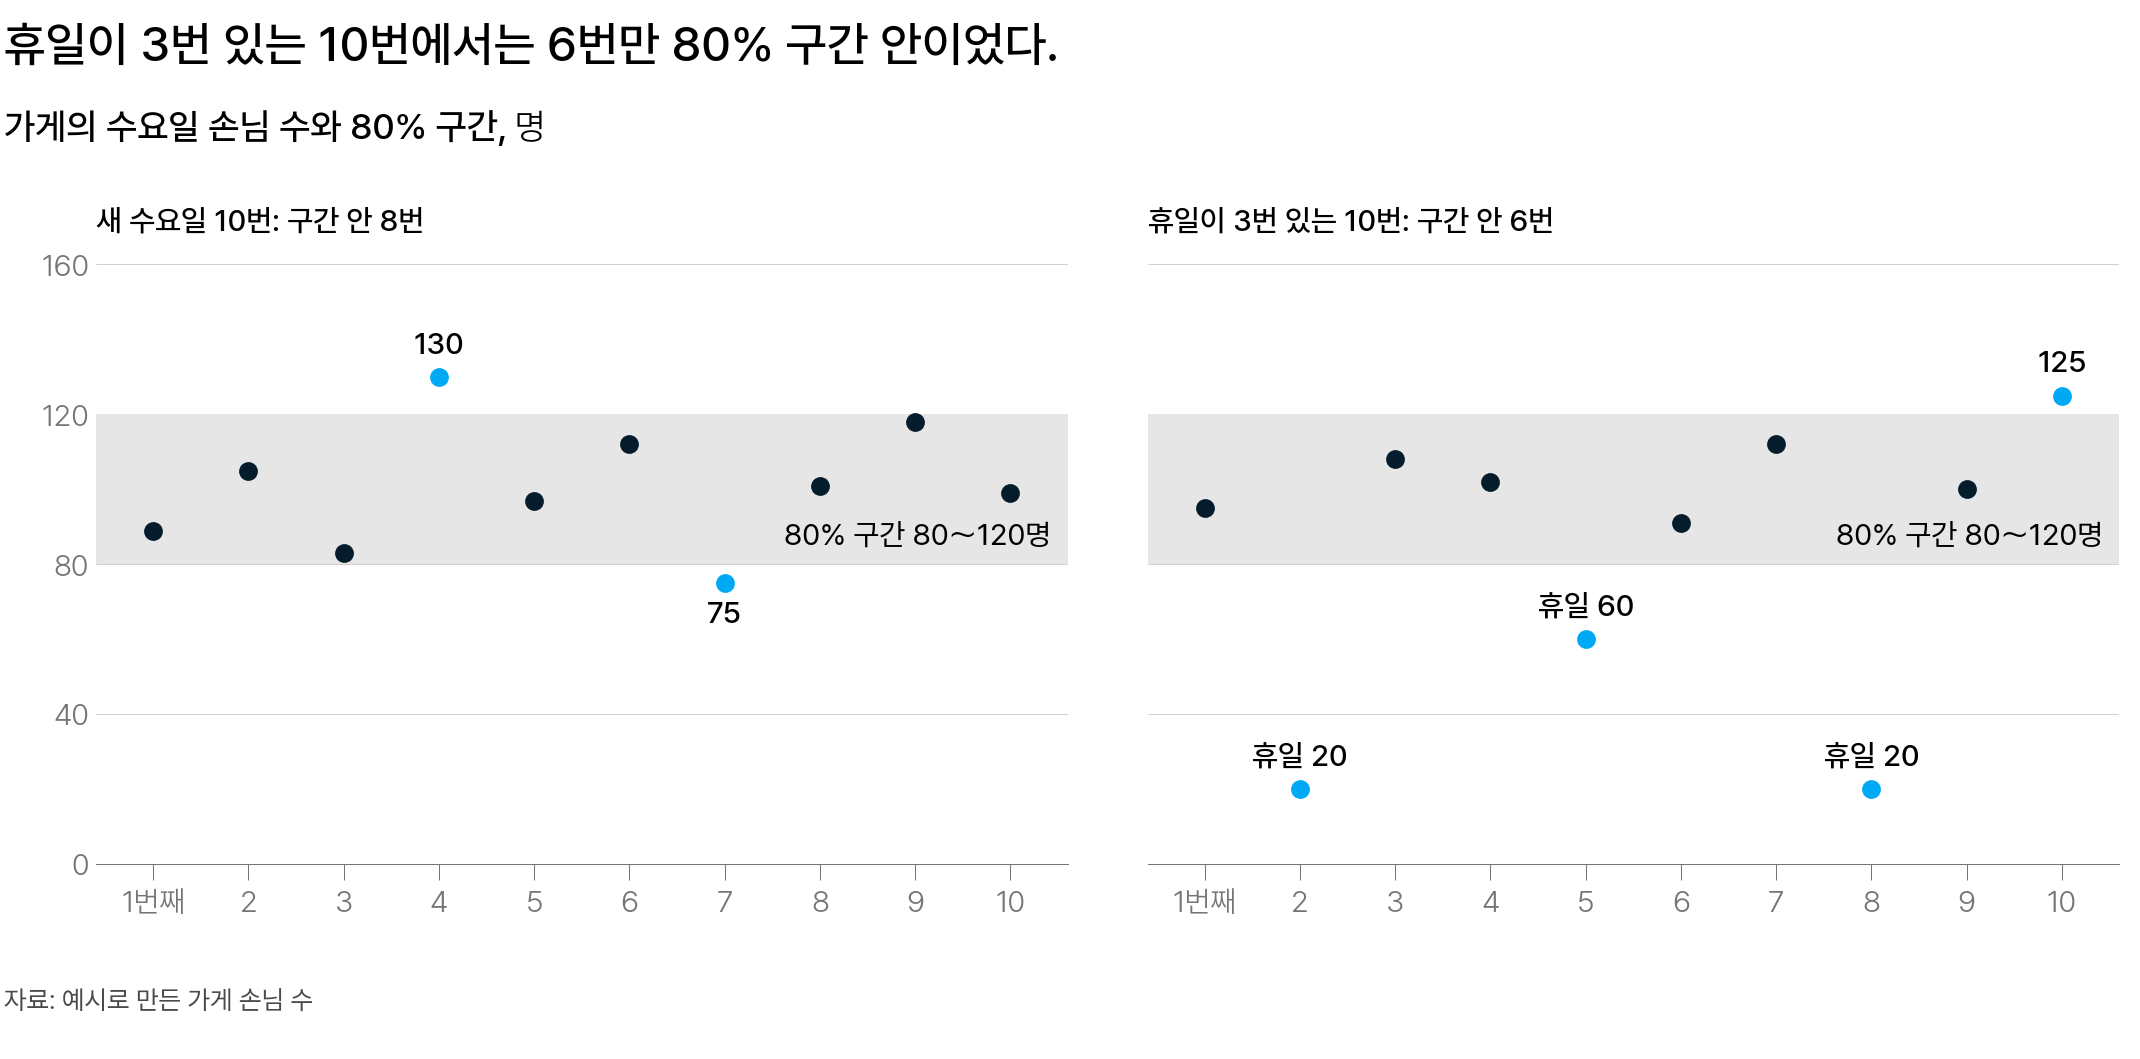

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 아래로 벗어난 세 점은 모두 휴일이고, 구간은 휴일에도 80～120명 그대로다</em></p>

휴일이 3번 있는 10번에서는 「안」이 6번, 「아래」가 3번, 「위」가 1번입니다.

따라서 포함률은 6 ÷ 10 = 60% 입니다. 아래로 벗어난 3번은 모두 휴일입니다.

이 구간은 휴일 여부를 쓰지 않고 정한 구간이라, 휴일에도 80～120명 그대로이기 때문입니다. Chronos-2 제로샷이 평일 공휴일을 여느 평일과 같은 크기로 예측한 것과 같은 까닭입니다.

그런데 두 10번을 합쳐 20번으로 계산하면 이 차이가 드러나지 않습니다.

| 기간 | 날 수 | 「안」인 날 | 포함률 |
|---|---:|---:|---:|
| 새 수요일 10번 | 10 | 8 | 80% |
| 휴일이 있는 10번 | 10 | 6 | 60% |
| 20번 전체 | 20 | 14 | 70% |

14 ÷ 20 = 70% 하나만 남기 때문입니다.

**휴일 당일과 나머지 날**

휴일이 있는 10번을 휴일 당일 3번과 휴일이 아닌 7번으로 한 번 더 나눕니다.

| 휴일이 있는 10번의 날 | 날 수 | 안 | 아래 | 위 | 포함률 |
|---|---:|---:|---:|---:|---:|
| 휴일 당일 | 3 | 0 | 3 | 0 | 0 ÷ 3 = 0% |
| 휴일이 아닌 날 | 7 | 6 | 0 | 1 | 6 ÷ 7 = 85.7% |

휴일 당일은 3번 모두 구간 아래입니다. 반면 휴일이 아닌 7번의 85.7% 는 명목 80% 보다 높아 보입니다.

하지만 7번에서는 하루만 달라져도 포함률이 1 ÷ 7, 곧 약 14% 포인트(%p) 달라집니다.

85.7 − 80 = 5.7%p 는 이 하루 차이보다 작아, 명목 80% 와 구별되지 않습니다.

> 포함률은 평균 하나로 보지 않고, 조건이 다른 날을 나눠 각각 명목 80% 와 비교합니다.

따라서 **휴일 당일의 준비량**은 이 구간으로 정하지 않고 따로 정합니다.

### 구간은 포함률과 구간 길이로 함께 평가한다 [필수]

포함률은 명목 80% 와 비교하고, 구간 길이는 같은 날로 계산한 다른 구간과 비교합니다.

> 좋은 구간은 명목 80% 만큼 포함하면서 짧은 구간입니다.

가게의 구간을 이 기준으로 나누면 네 가지 경우입니다.

| 포함률 | 구간 길이 | 해석 | 가게 예시 |
|---|---|---|---|
| 명목 80% 에 가깝다 | 짧다 | 구간이 짧은데도 명목 80% 만큼 포함했다 | 새 수요일 10번의 80～120명(80%, 40명) |
| 명목 80% 보다 높다 | 길다 | 구간이 필요보다 길 수 있다 | 새 수요일 10번의 0～200명(100%, 200명) |
| 명목 80% 보다 낮다 | 길다 | 구간을 넓혔는데도 포함률이 낮다 | 휴일이 있는 10번의 50～120명(70%, 70명) |
| 명목 80% 보다 낮다 | 짧다 | 구간이 짧거나, 실제가 구간 밖에 몰린 날이 있다 | 휴일이 있는 10번의 80～120명(60%, 40명) |

셋째 행의 50～120명은 휴일이 있는 10번에서 아래 끝만 50명으로 낮춘 구간입니다.

60명이 온 휴일 하루가 구간 안이 되어 포함률은 7 ÷ 10 = 70% 입니다.

길이는 120 − 50 = 70명으로 길어졌습니다. 그런데도 20명이 온 휴일 이틀은 여전히 구간 아래입니다.

따라서 포함률이 명목 80% 보다 낮으면 **어느 날에 벗어났는지**부터 확인합니다.

<div class="lms-summary">

**정리**

포함률은 실제가 구간 안에 있던 날의 비율이고, 명목 80% 와 비교합니다. 구간을 넓히기만 해도 오르므로 구간 길이를 함께 보고, 평균 하나로 요약하지 않고 조건이 다른 날을 나눠서 봅니다.

서울 지하철 100개 역의 구간도 포함률과 구간 길이를 함께 보고, 공휴일이 있는 주와 없는 주를 나눠서 확인합니다.

</div>

## 3. 서울 지하철 100개 역의 포함률

공휴일 열을 입력한 Chronos-2 의 80% 구간은 포함률도 80% 였을까요?

여기부터의 수는 모두 서울 지하철 100개 역의 실제 승차 인원과, 예측 원점 5개에서 얻은 예측으로 계산한 값입니다.

### 100개 역의 포함률은 어떻게 계산하는가 [필수]

계산하는 방법은 가게 예시와 같습니다. 실제가 80% 구간 안에 있던 날의 수를 전체 날의 수로 나눕니다.

달라지는 것은 무엇을 한 번으로 보는지와 구간입니다. 서울 지하철 자료에서는 다음에 해당합니다.

| 가게 예시 | 서울 지하철 100개 역 |
|---|---|
| 수요일 하루가 한 번 | 역 하나의 하루가 점 하나 |
| 새 수요일 10번 | 예측 원점 하나에 100개 역 × 7일 = 700점 |
| 구간은 80～120명 하나 | 점마다 `"0.1"` 열과 `"0.9"` 열이 다르다 |

따라서 원점 하나의 포함률은 700점 가운데 실제 승차가 `"0.1"` 열과 `"0.9"` 열 사이에 있는 점의 비율입니다. **점 하나**를 「역·날」이라고도 합니다.

예측 표는 Chronos-2 제로샷과 Chronos-2 + 공휴일이 원점 5개에서 낸 것입니다. 가게에서 휴일이 있는 10번의 포함률을 따로 구했듯이, 원점 5개도 채점 7일에 평일 공휴일이 있는 주와 없는 주로 나눕니다.

| 채점한 주 | 예측 원점 |
|---|---|
| 공휴일 없는 두 주 | 2025-12-10 · 2026-06-24 |
| 공휴일 있는 세 주 | 2025-08-13 · 2025-10-01 · 2026-02-11 |

평일 공휴일은 공휴일이면서 월～금인 날입니다. 세 주에 6일 있습니다(광복절 · 개천절 · 추석 연휴 이틀 · 설 연휴 이틀).

**강남역의 두 주**

100개 역으로 넓히기 전에 강남역 한 역부터 확인합니다.

공휴일 없는 주(원점 2026-06-24)는 7일 가운데 6일이 Chronos-2 + 공휴일의 구간 안이었습니다. 반면 설 연휴가 있는 주(원점 2026-02-11)는 3일뿐이었습니다.

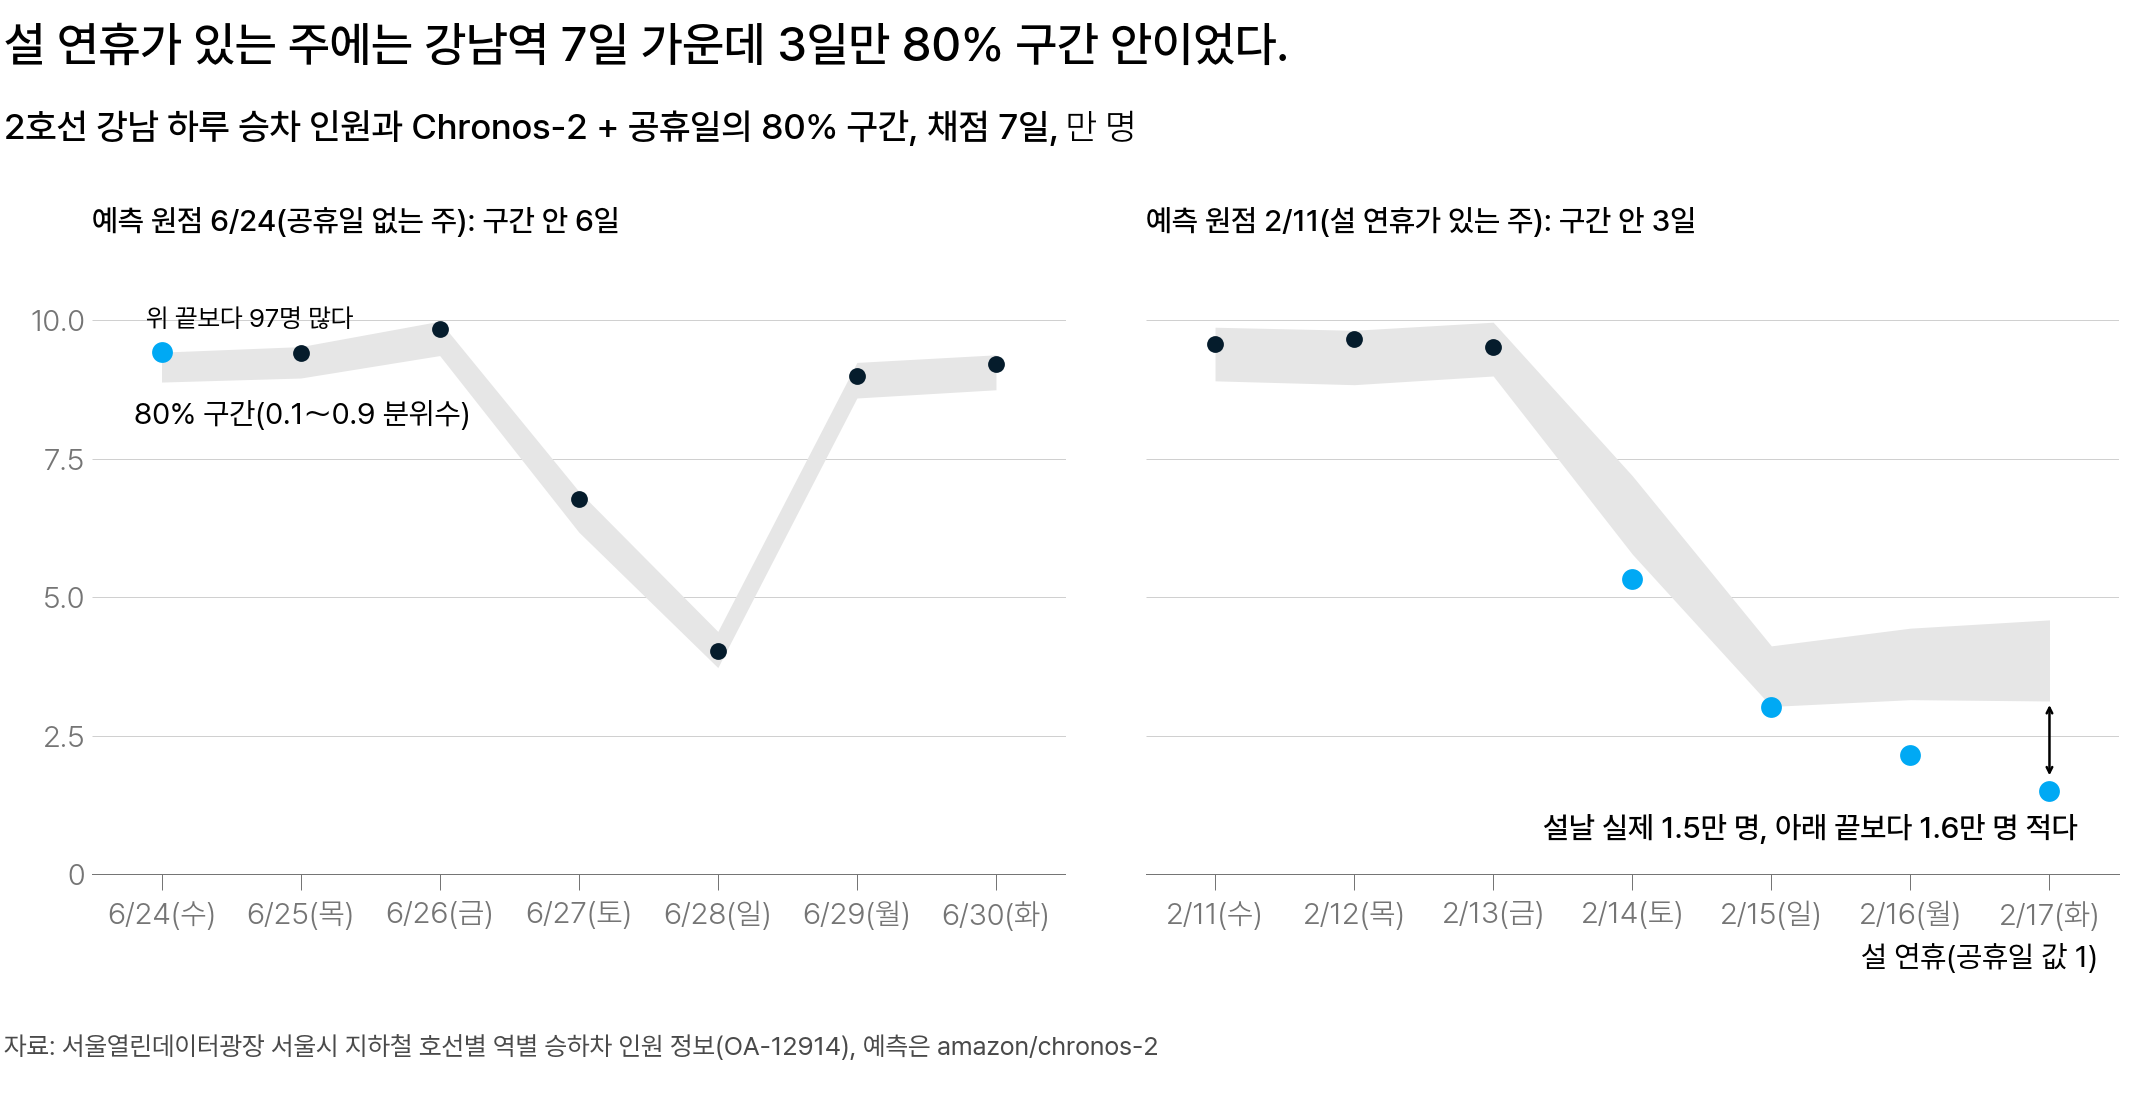

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 설 연휴 이틀은 구간이 평소보다 낮게 나왔는데도 실제 승차 인원이 아래 끝보다 적었다</em></p>

설 연휴 이틀(2월 16 · 17일)은 `holiday` 열이 1 이라, 구간이 다른 평일보다 낮게 나왔습니다.

그런데도 2월 17일의 실제 승차 14,973명은 아래 끝 31,282명보다 적었습니다.

아래 셀은 설 연휴가 있는 주의 7일이 구간 안인지 하루씩 확인합니다.

In [ ]:
# 강남역 원점 2026-02-11 의 7일 가운데 실제 승차가 Chronos-2 + 공휴일 80% 구간 안인 날이 며칠인지 센다
import numpy as np

y = np.array([95623, 96519, 95092, 53284, 30140, 21453, 14973])     # 실제 승차(명), 2/11 ~ 2/17
q01 = np.array([89033, 88339, 89908, 57783, 30296, 31522, 31282])   # 0.1 분위수 열
q09 = np.array([98701, 98148, 99609, 71923, 41223, 44419, 45911])   # 0.9 분위수 열
inside = (y >= q01) & (y <= q09)                                    # 두 끝을 포함해 구간 안
print(f"결론: 7일 가운데 {inside.sum()}일이 구간 안, 포함률 {inside.mean():.1%}")
print(f"아래 끝보다 적은 날 {(y < q01).sum()}일, 위 끝보다 많은 날 {(y > q09).sum()}일")

실행 결과는 구간 안 3일, 아래 끝보다 적은 날 4일입니다. 따라서 이 주의 강남역 포함률은 3 ÷ 7 = 42.9% 입니다.

4일 가운데 이틀은 설 연휴이고, 나머지 이틀은 연휴 앞 주말(2월 14 · 15일)입니다. 이 주말은 `holiday` 열이 0 이라 구간이 낮아지지 않았습니다.

그런데 한 역의 7일로는 하루만 달라져도 포함률이 약 14%p 달라집니다. 그래서 100개 역의 700점으로 넓혀 계산합니다.

예측 표 `fc` 에 실제 승차 `y` 열을 더해, 행마다 실제 승차가 두 끝 사이에 있는지 확인합니다. 아래는 원점 2026-02-11 에 Chronos-2 + 공휴일로 얻은 `fc` 의 세 행입니다(단위: 명).

| `item_id` | `timestamp` | 0.1 열(아래 끝) | 0.9 열(위 끝) | `y`(실제 승차) | 구간 안·밖 |
|---|---|---:|---:|---:|---|
| 0(2호선 강남) | 2026-02-12 | 88,339 | 98,148 | 96,519 | 안 |
| 0(2호선 강남) | 2026-02-17 | 31,282 | 45,911 | 14,973 | 아래 |
| 6(2호선 삼성) | 2026-02-12 | 56,195 | 64,121 | 69,709 | 위 |

`fc` 의 한 행이 점 하나입니다.

> 구간 안인 행의 수를 700 으로 나눈 값이 그 원점의 포함률입니다.

예를 들어 공휴일 없는 주인 원점 2026-06-24 는 「안」이 554행이라, 포함률이 554 ÷ 700 = 79.1% 입니다.

<details class="lms-extra"><summary>자세히 — 포함률을 구하는 코드</summary>

배열 두 개를 씁니다. `y` 는 원점 하나의 실제 승차가 있는 100개 역 × 7일 배열입니다. 역이 행, 날이 열입니다.

`q` 는 예측 표의 분위수 아홉 열이 있는 100개 역 × 7일 × 9열 배열입니다. `q` 의 마지막 차원이 0.1 열부터 0.9 열까지입니다.

- `q[..., 0]`: 모든 역·날의 0.1 열, 곧 아래 끝(100 × 7)
- `q[..., -1]`: 모든 역·날의 0.9 열, 곧 위 끝(100 × 7)
- `(y >= q[..., 0]) & (y <= q[..., -1])`: 두 끝을 포함해 구간 안이면 참인 100 × 7 표
- `.mean()`: 참을 1, 거짓을 0 으로 바꿔 평균한 값, 곧 700점 가운데 구간 안의 비율

작은 수로 확인합니다. 3점의 실제가 10 · 20 · 30 이고 두 끝이 (5, 15) · (21, 25) · (25, 35) 라면 구간 안은 참 · 거짓 · 참입니다. 평균은 2 ÷ 3 = 66.7% 입니다. 아래 끝과 같은 값도 구간 안이므로 `>=`·`<=` 를 씁니다.

구간 길이(0.9 열 − 0.1 열)의 평균은 `(q[..., -1] - q[..., 0]).mean()` 으로 구합니다. 원점마다 포함률과 평균 구간 길이를 구한 뒤, 공휴일 없는 두 주와 공휴일 있는 세 주로 나눠 평균합니다.

예측 표가 역 하나의 하루가 한 행인 롱 포맷 `fc` 이고 실제 승차가 `y` 열에 있다면, 같은 계산은 `((fc["y"] >= fc["0.1"]) & (fc["y"] <= fc["0.9"])).mean()` 입니다. 원점이 여럿이면 원점별로 평균을 구합니다.

**설 연휴 앞 주말의 미래 입력**

`future_df` 의 한 행은 역 하나의 채점 하루입니다. 강남역의 2월 14～17일 네 행에서 `holiday` 열은 차례로 0 · 0 · 1 · 1 입니다.

2월 14 · 15일은 설 연휴 앞 주말이지만 `holiday` 열이 0 입니다. 그래서 구간이 앞 주 토 · 일의 승차(65,956명 · 36,589명)를 포함하는 범위로 나왔습니다. 실제 승차는 그보다 적어, 아래 끝보다 토요일에 4,499명, 일요일에 156명 적었습니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 점 예측에서 두 끝까지의 거리</summary>

시계열 과목에서는 예측구간을 점 예측에 오차 크기를 더하고 빼서 만들었습니다. Chronos-2 의 예측 표에는 두 끝이 분위수 열로 바로 있습니다.

시계열 과목의 95% 예측구간은 이 식으로 구했습니다.

$$
\hat{y}_{t+h} \pm 1.96 \times \sigma_h
$$

- $\hat{y}_{t+h}$: 마지막 시각 $t$ 에서 $h$ 시각 뒤의 점 예측
- $\sigma_h$: 그 예측 오차의 표준편차
- $1.96$: 정규분포에서 가운데 95% 를 남기는 배수

SARIMA 의 11월 17일 0시 예측($h = 1$)은 점 예측 654대, $\sigma_1$ 176.5대였습니다. 1.96 × 176.5 = 346대라 구간은 654 ± 346, 곧 308～1,000대였습니다.

반면 분위수 열로 정한 두 끝은 점 예측까지의 거리가 서로 다를 수 있습니다. 강남역 6월 26일은 0.5 열에서 아래 끝까지 2,993명, 위 끝까지 3,207명입니다. 한쪽으로 크게 벗어나는 일이 잦은 자료에서는 아래 그림처럼 두 거리의 차이가 더 커집니다.

<img src="https://scikit-learn.org/stable/_images/sphx_glr_plot_quantile_regression_003.png" alt="한쪽으로 크게 벗어나는 자료의 0.05·0.5·0.95 분위수 직선" width="480" height="360"/>
<p align="center"><em>▲ 가끔 위로 크게 벗어나는 값이 나오는 자료에 그은 0.05·0.5·0.95 분위수 직선. 0.95 선(초록)은 0.5 선(주황)에서 멀고 0.05 선(파랑)은 가깝다. 파랑과 초록 사이가 90% 구간이고, + 모양 점이 구간 밖이다 (출처: scikit-learn 공식 예제 Quantile regression, 식으로 만든 자료)</em></p>

scikit-learn 이 식으로 만든 자료에 분위수 직선을 그은 그림입니다. Chronos-2 의 예측을 그린 그림은 아닙니다.

| 그림의 글자 | 뜻 |
|---|---|
| Quantile: 0.05 · 0.5 · 0.95 | 0.05 · 0.5 · 0.95 분위수를 이은 직선(파랑 · 주황 · 초록) |
| True mean | 자료를 만든 식의 평균(검은 파선) |
| Inside interval · Outside interval | 파란 선과 초록 선 사이의 점(동그라미)과 그 밖의 점(+ 모양) |

제목의 asymmetric 은 한쪽으로 치우쳤다는 뜻입니다.

가게의 세 분위수는 100명에서 아래로 20명, 위로 20명이라 두 거리가 같습니다. 이 그림의 자료는 위쪽 거리가 더 깁니다.

</details>

> **[문제] Chronos-2 + 공휴일의 원점 2026-02-11(공휴일 있는 주)에서 700점은 80% 구간 안 413점, 아래 끝보다 적은 점 262점, 위 끝보다 많은 점 25점이었습니다. 이 원점의 포함률은?**
>
> 1. 약 37%
> 2. 약 59%
> 3. 약 96%

**직접 해보기: 700점을 한 점씩 세어 포함률 구하기**

아래 위젯은 서울 지하철 100개 역의 7일, 곧 700점을 한 점씩 셉니다. 회색 막대는 Chronos-2 + 공휴일의 80% 구간이고, 원은 그 점의 실제 승차 인원입니다. 센 점에는 결과에 따라 색이 남습니다.

1. **해 보기.** `한 점` 을 다섯 번 누릅니다.
2. **관찰.** 다섯째 점에서 `지금 센 점` 의 결과가 `위 끝보다 많음` 으로 바뀝니다. 이때 `포함률` 이 100.0% 에서 80.0% 로 낮아지는 것을 확인합니다.
3. **확인 질문.** `700점 모두` 를 누르고 `채점한 주` 를 `설 연휴가 있는 주(2026-02-11)` 로 바꿉니다. 오른쪽 `구간 안` 의 수가 가장 작은 이틀은 언제이고, 몇 개 역일까요?

In [ ]:
# 인터랙티브 위젯 — 셀을 실행하면 나타납니다 (인터넷 연결 필요)
# 아래가 잘려 보이면 height 값을 키우세요.
from IPython.display import IFrame
IFrame("https://aic-data.aiffel.io/api/widget-file/deep-time-series/coverage-lab.html", width=980, height=520)

<details class="lms-answer"><summary>답 확인 — 구간 안인 역이 가장 적은 이틀</summary>

설 연휴인 2월 16일(월)과 17일(화)입니다. 구간 안인 역은 16일에 11개, 17일에 9개입니다. 날짜 차례로는 94 · 89 · 94 · 39 · 77 · 11 · 9개 역이 구간 안입니다.

이 주의 700점은 `구간 안` 413 · `아래 끝보다 적음` 262 · `위 끝보다 많음` 25 입니다. 포함률은 413 ÷ 700 = 59.0% 입니다. 공휴일이 없는 주는 554 · 9 · 137 이라 554 ÷ 700 = 79.1% 였습니다. 주 전체의 59.0% 만으로는 설 연휴 이틀의 11개 · 9개 역이 드러나지 않습니다.

`채점한 주` 를 `공휴일이 없는 주(2026-06-24)` 로 다시 바꿉니다. 여기서 `모델` 을 `Chronos-2 제로샷` 으로 바꾸면 포함률이 79.1% 에서 88.0% 로 높아집니다. 그런데 `평균 구간 길이` 도 2,918명에서 3,462명으로 길어집니다. 포함률이 높은 까닭이 긴 구간인지는 「포함률이 더 높은 구간이 더 좋은 구간인가」에서 확인합니다.

</details>

### 공휴일이 있는 주와 없는 주의 포함률 [필수]

공휴일 없는 두 주의 포함률은 두 원점의 2 × 700 = 1,400점을 합쳐 구한 값입니다.

공휴일 있는 세 주는 3 × 700 = 2,100점입니다.

> **[예측] Chronos-2 + 공휴일은 공휴일 열을 입력한 예측입니다. 공휴일 있는 세 주의 2,100점 가운데 실제 승차가 80% 구간 안에 있던 점은 몇 % 일까요?**
>
> 1. 80% 가까이
> 2. 60～70%
> 3. 50% 아래
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

둘째 보기가 맞습니다. 포함률은 공휴일 없는 두 주가 79.5%, 공휴일 있는 세 주가 66.4% 였습니다.

| Chronos-2 + 공휴일 | 점의 수 | 구간 안 | 포함률 | 명목 80% 와의 차이 |
|---|---:|---:|---:|---:|
| 공휴일 없는 두 주 | 1,400 | 1,113 | 79.5% | 0.5%p 낮다 |
| 공휴일 있는 세 주 | 2,100 | 1,395 | 66.4% | 13.6%p 낮다 |
| 원점 5개 전체 | 3,500 | 2,508 | 71.7% | 8.3%p 낮다 |

그런데 원점 5개 전체의 71.7% 하나만 전달하면 66.4% 가 드러나지 않습니다.

가게에서 80% 와 60% 가 70% 하나가 된 것과 같습니다.

두 값 가운데 79.5% 는 명목 80% 와 같다고 봅니다. 포함률은 점의 수가 한정되어 있어 우연히 달라지기 때문입니다.

점마다 구간 안일 확률이 80% 인 구간이어도, 1,400점이면 대개 77.9～82.1% 사이로 나옵니다(계산은 아래 「자세히」).

반면 66.4% 는 2,100점의 범위 78.3～81.7% 에서 가장 낮은 78.3% 보다 11.9%p 낮습니다. 이 차이는 우연으로 볼 수 없습니다.

> 포함률은 공휴일이 있는 주와 없는 주를 나눠 각각 명목 80% 와 비교합니다.

<details class="lms-extra"><summary>자세히 — 79.5% 를 명목 80% 와 같다고 보는 까닭</summary>

점마다 구간 안일 확률이 80% 인 구간이어도, 계산한 포함률은 딱 80.0% 가 나오지 않습니다. 점마다 구간 안에 있을지가 조금씩 운에 달려 있기 때문입니다. 그러면 80% 에서 얼마나 떨어져야 모자란다고 볼까요?

점 하나가 구간 안에 있을 확률이 0.8 이고 점끼리 서로 영향을 주지 않는다고 가정합니다. $N$ 점 가운데 구간 안 점 수는 이항분포를 따르고, 그 표준편차는 $\sqrt{N \times 0.8 \times 0.2}$ 점입니다.

공휴일 없는 두 주라면 평균은 1,400 × 0.8 = 1,120점이고, 표준편차는 $\sqrt{1{,}400 \times 0.8 \times 0.2} \approx 15.0$ 점입니다. 정규분포에 가깝다고 보면 약 95% 가 평균 ± 표준편차 두 배 안에 들어옵니다. 두 배인 30점을 1,400 으로 나누면 2.1%p 라, 80 ± 2.1 = 77.9～82.1% 가 우연한 변동으로 볼 수 있는 범위입니다. 아래 표의 나머지 두 행도 같은 계산입니다.

| 채점한 주 | 점의 수 $N$ | 표준편차 | 평균 ± 표준편차 두 배(포함률) | Chronos-2 + 공휴일 포함률 |
|---|---:|---:|---:|---:|
| 공휴일 없는 두 주 | 1,400 | 15.0점 | 77.9～82.1% | 79.5% |
| 공휴일 있는 세 주 | 2,100 | 18.3점 | 78.3～81.7% | 66.4% |
| 한 주 | 700 | 10.6점 | 77.0～83.0% | 원점별 59.0～79.9% |

점의 수가 적을수록 범위는 넓습니다. 66.4% 는 범위가 가장 넓은 한 주 700점의 가장 낮은 값 77.0% 보다도 낮습니다.

다만 이 범위는 어림입니다. 실제로는 같은 날의 100개 역이 함께 움직입니다. 평일 공휴일이면 거의 모든 역의 승차가 같이 줄어듭니다. 그래서 점끼리 영향을 주지 않는다는 가정이 맞지 않고, 실제 변동은 표의 범위보다 큽니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Binomial_distribution_pmf.svg" alt="이항분포 세 개의 확률" width="560" height="373"/>
<p align="center"><em>▲ 이항분포 세 개. 가로축이 n 번 시도 가운데 성공 횟수, 세로축이 그 횟수가 나올 확률이다. 성공 확률 p 와 시도 횟수 n 이 같아도 성공 횟수는 가운데 값 주변에서 달라진다 (출처: Wikimedia Commons, Binomial distribution pmf.svg)</em></p>

| 그림의 글자 | 뜻 | 이 계산에서는 |
|---|---|---|
| p | 한 번 시도가 성공할 확률 | 점 하나가 구간 안에 있을 확률 0.8 |
| n | 시도 횟수 | 점의 수 $N$ |
| 가로축의 수 | 성공 횟수 | 구간 안 점 수 |

범례의 세 항목은 p 와 n 이 다른 분포 셋입니다.

</details>

**공휴일 없는 두 주에서 구간 밖 점이 벗어난 쪽**

포함률 79.5% 는 명목 80% 에 가깝습니다. 그런데 구간 밖 287점 가운데 265점은 실제 승차가 위 끝보다 많았습니다.

| 공휴일 없는 두 주 1,400점 | 점의 수 | 비율 |
|---|---:|---:|
| 구간 안 | 1,113 | 79.5% |
| 아래 끝보다 적은 점 | 22 | 1.6% |
| 위 끝보다 많은 점 | 265 | 18.9% |

명목 80% 대로라면 구간 밖 20% 는 위와 아래로 10% 씩 벗어납니다. 그런데 실제로는 위쪽만 18.9% 였습니다. 즉, 위 끝만큼 인력을 두었다면 다섯 번에 한 번은 모자랐습니다.

가게에서 7번째 날을 125명으로 바꾼 표와 같은 경우입니다.

이 265점을 요일로 나누면, 179점이 금요일과 토요일 4일에 있었습니다.

이 4일은 400점 가운데 221점(약 55%)만 구간 안이었습니다.

반면 나머지 10일은 1,000점 가운데 892점(89.2%)이 구간 안이었습니다.

다만 18.9% 는 두 주만으로 구한 값이라, 위 끝을 높일 근거로는 부족합니다. 그래서 공휴일 없는 주가 지날 때마다 다시 계산합니다.

따라서 공휴일 없는 주에는 구간을 그대로 쓰고, **위 끝보다 많은 점 18.9%** 를 함께 전달합니다. 그 점이 금요일과 토요일에 몰려 있었다는 것도 함께 적습니다.

### 포함률이 더 높은 구간이 더 좋은 구간인가 [필수]

포함률이 더 높다고 더 좋은 구간은 아닙니다. 구간이 더 길어서 포함률이 높은 것일 수 있기 때문입니다.

공휴일 없는 주인 원점 2026-06-24 에서 두 모델의 80% 구간을 비교합니다. **평균 구간 길이**는 700점마다 구한 구간 길이(위 끝 − 아래 끝)를 평균한 값입니다.

| 원점 2026-06-24 | 포함률 | 평균 구간 길이 | 해석 |
|---|---:|---:|---|
| Chronos-2 제로샷 | 88.0%(616점) | 3,462명 | 명목 80% 보다 높고 길다 |
| Chronos-2 + 공휴일 | 79.1%(554점) | 2,918명 | 명목 80% 에 가깝고 짧다 |

포함률은 제로샷이 더 높습니다. 그런데 평균 구간 길이도 제로샷이 3,462 − 2,918 = 544명 깁니다.

비로는 3,462 ÷ 2,918 ≈ 1.19배입니다.

가게의 0～200명 구간처럼, 구간을 넓혀서 포함률이 높아진 경우입니다.

다만 길이는 같은 원점의 같은 700점끼리 비교합니다. 승차가 많은 역일수록 구간이 길기 때문입니다.

따라서 이 원점에서는 **명목 80% 에 가깝고 짧은** Chronos-2 + 공휴일 구간을 전달합니다.

<details class="lms-extra"><summary>자세히 — 구간 길이가 역마다 다른 까닭</summary>

구간 길이는 명 단위라 승차가 많은 역일수록 길게 나옵니다.

아래 표의 한 행은 역 하나이고, 값은 Chronos-2 + 공휴일 원점 5개의 35점(5 × 7일)에서 평균한 것입니다. 상대 구간 길이는 평균 구간 길이를 0.5 열 평균으로 나눈 값입니다.

| 역 | 평균 구간 길이 | 0.5 열 평균 | 상대 구간 길이 |
|---|---:|---:|---:|
| 2호선 잠실 | 13,680명 | 75,116명 | 0.18 |
| 2호선 강남 | 9,504명 | 69,955명 | 0.14 |
| 2호선 신림 | 5,404명 | 49,765명 | 0.11 |
| 7호선 청담 | 2,319명 | 15,122명 | 0.15 |

네 역은 0.5 열 평균이 큰 차례가 잠실·강남·신림·청담이고, 평균 구간 길이도 같은 차례로 깁니다. 잠실의 평균 구간 길이는 청담의 5.9배입니다. 반면 상대 구간 길이는 0.11～0.18 로 이 차례를 따르지 않습니다.

상대 구간 길이는 시계열 과목에서 구간 길이를 점 예측으로 나눠 구한 값과 같은 계산입니다. 그래서 규모가 다른 역끼리도 비교할 수 있습니다.

100개 역 전체에서도 결과가 같습니다. 역의 평균 승차와 구간 길이의 순위상관은 0.81 이고, 평균 승차와 상대 구간 길이의 순위상관은 0.08 입니다. 순위상관은 두 값의 순서가 함께 움직이는 정도이고, −1～1 사이의 값입니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Seoul-metro-216-Jamsil-station-platform-20180914-141514.jpg" alt="2호선 잠실역 승강장" width="480" height="270"/>
<p align="center"><em>▲ 2호선 잠실역 승강장. 원점 5개의 채점 35일에 하루 평균 74,094명이 탔다 (출처: Wikimedia Commons, Seoul-metro-216-Jamsil-station-platform-20180914-141514.jpg)</em></p>

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Seoul-metro-729-Cheongdam-station-platform-20181123-105504.jpg" alt="7호선 청담역 승강장" width="480" height="270"/>
<p align="center"><em>▲ 7호선 청담역 승강장. 같은 35일에 하루 평균 14,643명이 탔다. 잠실 74,094명은 이 값의 5.1배다 (출처: Wikimedia Commons, Seoul-metro-729-Cheongdam-station-platform-20181123-105504.jpg)</em></p>

평균 구간 길이는 이렇게 역마다 다른 길이를 700점에서 평균한 값입니다. 그래서 두 모델은 같은 원점, 같은 700점에서 구한 평균끼리 비교합니다.

</details>

> **[문제] 포함률이 더 높은 구간과 더 짧은 구간**
>
> 원점 2026-06-24(공휴일 없는 주)에서 제로샷 80% 구간은 포함률 88.0%, 평균 구간 길이 3,462명이었습니다. Chronos-2 + 공휴일은 포함률 79.1%, 평균 구간 길이 2,918명이었습니다. 이 원점의 인력 계획에 어느 구간을 전달할지, 그리고 왜 포함률 옆에 구간 길이를 함께 적는지 두 문장으로 적어 보세요.

공휴일 있는 세 주는 반대입니다. Chronos-2 + 공휴일의 구간이 제로샷의 1.52배로 더 깁니다.

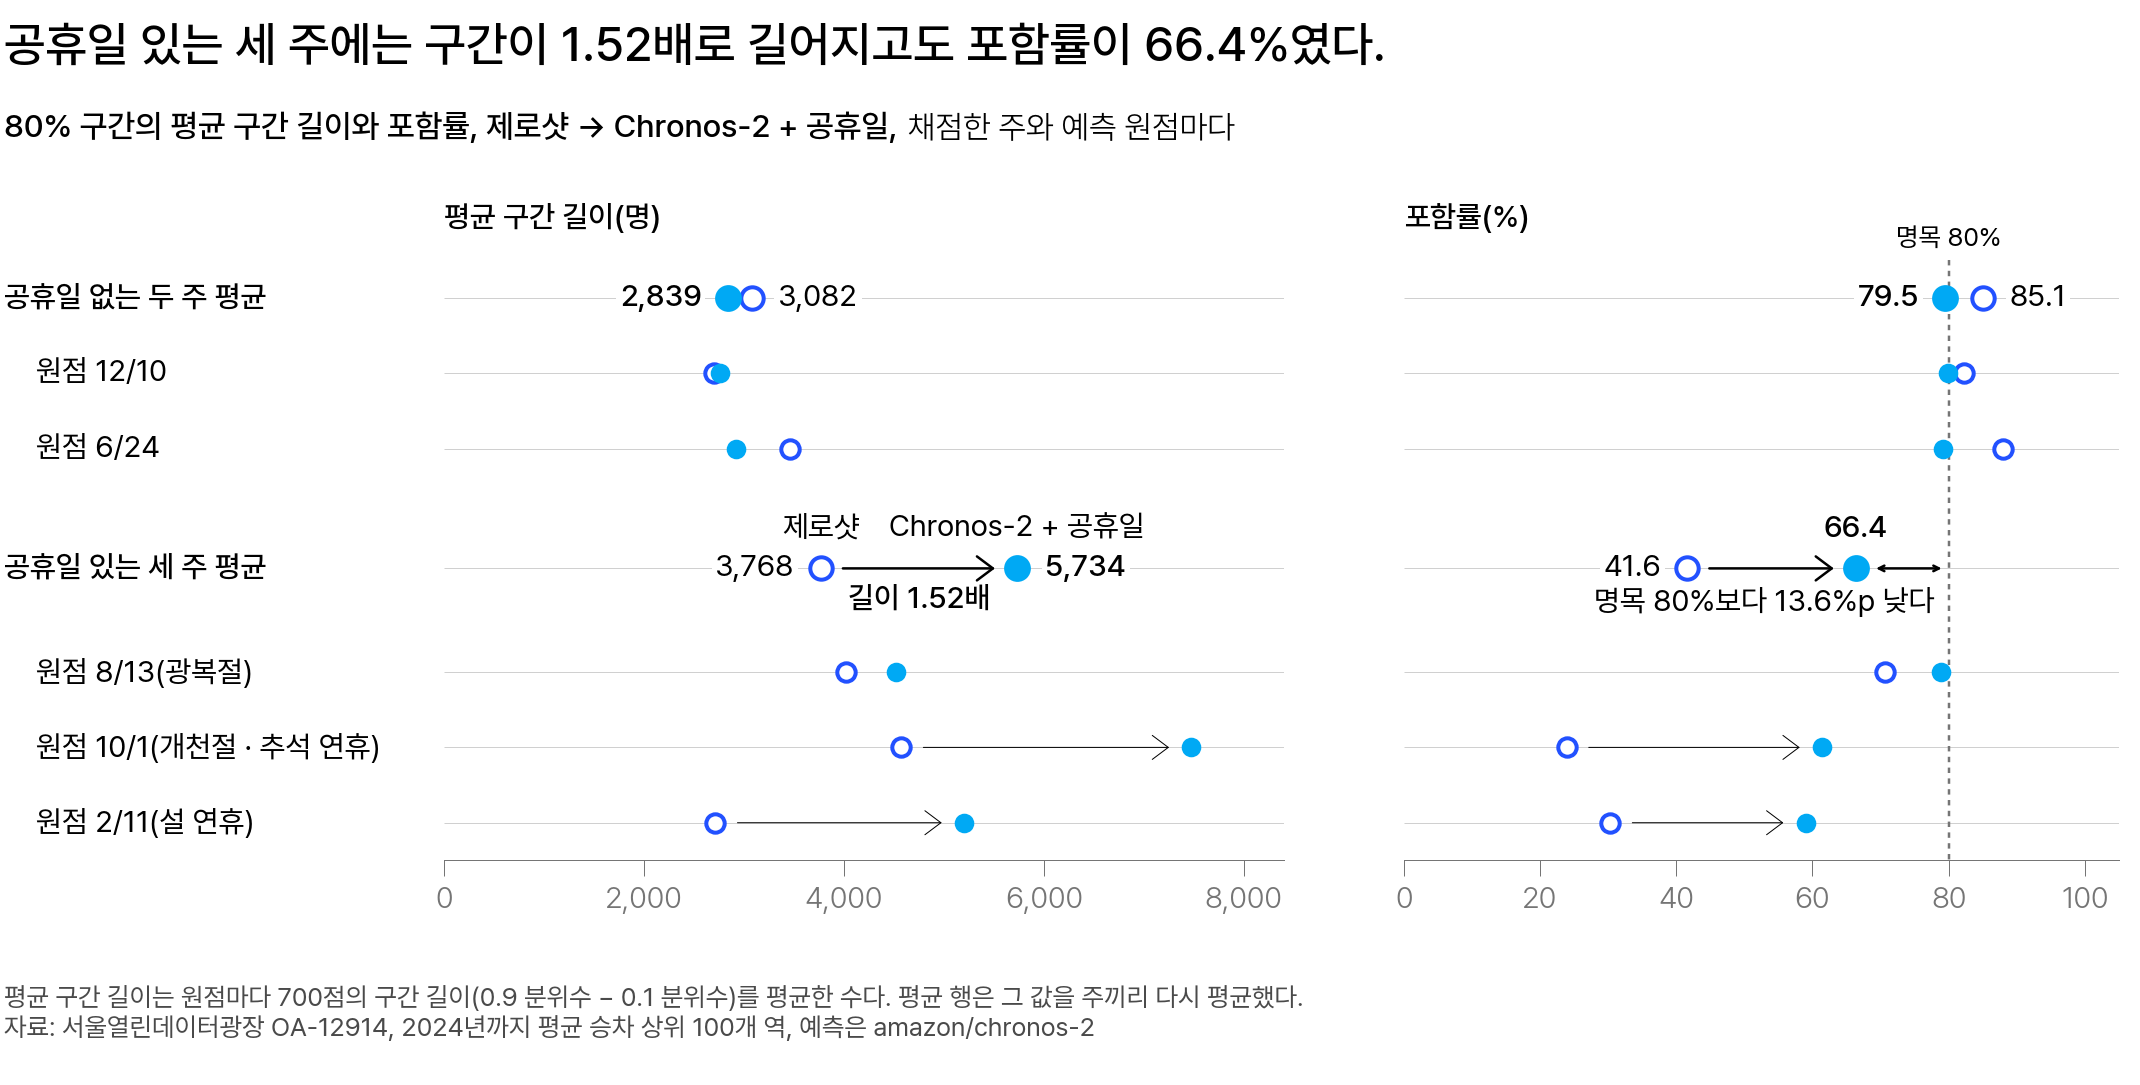

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 속 빈 원이 제로샷, 채운 점이 Chronos-2 + 공휴일이다. 공휴일 없는 두 주 평균은 구간이 짧아지며 명목 80% 로 내려왔고, 공휴일 있는 세 주 평균은 길어지고도 명목 80% 에 못 미쳤다</em></p>

그림에서 공휴일 없는 두 주의 평균 구간 길이는 3,082명에서 2,839명으로 짧아졌습니다. 제로샷의 0.92배입니다.

반면 공휴일 있는 세 주는 3,768명에서 5,734명으로 길어졌습니다.

이 세 주의 포함률은 제로샷의 41.6%(873 ÷ 2,100)에서 66.4% 로 높아졌습니다.

하지만 명목 80% 에는 13.6%p 못 미칩니다.

이 결과는 「2. 포함률과 구간 길이」의 네 가지 경우 가운데 셋째입니다. 가게의 50～120명 구간처럼, 구간이 길어졌는데도 포함률이 명목 80% 보다 낮습니다.

여기서 확인한 사실은 구간이 길어졌다는 것까지입니다. 까닭은 평일 공휴일에 승차가 얼마나 줄지가 날과 역마다 달라서라고 볼 수 있습니다.

> 공휴일 있는 세 주에는 구간이 1.52배로 길어지고도 포함률은 66.4% 였습니다.

<details class="lms-extra"><summary>더 깊이 — 보고서의 80% 구간 그림 읽기</summary>

아래는 Chronos-2 기술 보고서의 그림입니다. 자료는 서울 지하철과 다른 매장 판매량입니다.

같은 모델의 80% 구간을 보고서가 어떻게 그렸는지 확인하려고 실었습니다.

<img src="https://arxiv.org/html/2510.15821v1/rossmann.svg" alt="공변량 없이 낸 예측과 공변량을 함께 입력한 예측의 80% 예측구간" width="640" height="448"/>
<p align="center"><em>▲ 매장 판매량에 Chronos-2 가 낸 80% 예측구간(분홍). 맨 위 그래프는 판매량만, 둘째 그래프는 판촉·공휴일 같은 공변량(셋째 그래프부터)까지 입력한 예측이다 (출처: Ansari 외, Chronos-2: From Univariate to Universal Forecasting, arXiv 2510.15821, Figure 7)</em></p>

그림은 그래프 일곱 개로 되어 있고, 가로축은 모두 날짜입니다. 위에서부터 차례로 읽습니다.

| 그림의 영어 이름 | 뜻 |
|---|---|
| Sales | 매장 판매량. 첫째 · 둘째 그래프의 파란 선이고, 예측하려는 값이다 |
| Forecast (Univariate) | 판매량의 과거만 입력한 예측. 맨 위 그래프의 분홍 선 |
| Forecast (ICL) | 셋째부터 일곱째 그래프까지의 값도 함께 입력한 예측. 둘째 그래프의 분홍 선 |
| Open · Promo | 매장이 문을 열었는지, 판촉을 했는지를 나타내는 값 |
| SchoolHoliday · StateHoliday | 방학인지, 공휴일인지를 나타내는 값 |
| Customers | 손님 수 |

공변량(covariate)은 예측하려는 값과 함께 모델에 입력하는 다른 열입니다. 이 그림에서는 셋째부터 일곱째 그래프까지가 공변량입니다.

세로 점선이 예측을 시작하는 날이고, 서울 지하철의 예측 원점과 같은 뜻입니다.

Customers 선은 점선에서 끝나고, 나머지 네 선은 점선 뒤에도 이어집니다. 앞으로의 손님 수는 미리 알 수 없는 값이라, 점선 뒤에는 입력할 수 없기 때문입니다.

분홍 선은 0.5 분위수이고, 옅은 분홍 범위가 80% 예측구간입니다.

가게 예시에 적용하면, 날마다 80～120명 같은 범위를 하나씩 칠한 그림입니다.

이 그림만으로는 공변량을 입력하면 구간이 늘 짧아진다고 생각하기 쉽습니다.

보고서는 공변량을 쓴 예측이 더 정확하다고만 설명하고, 구간 길이를 수로 비교하지는 않았습니다.

반면 서울 지하철의 공휴일 있는 세 주에서는 구간이 1.52배로 길어졌습니다.

보고서의 모델과 80% 구간의 뜻은 이 과정에서 쓰는 것과 같습니다. 보고서에는 포함률을 계산한 결과가 없어, 여기서는 700점으로 직접 구했습니다.

</details>

### 평일 공휴일 당일의 인력은 구간으로 정하지 않는다 [필수]

공휴일 있는 세 주의 포함률 66.4% 를 날로 나눕니다. 평일 공휴일 당일 600점은 46.5% 이고, 당일을 뺀 1,500점은 74.4% 입니다.

| 공휴일 있는 세 주의 날 | 점의 수 | 구간 안 | 포함률 |
|---|---:|---:|---:|
| 세 주 전체 | 2,100 | 1,395 | 66.4% |
| 평일 공휴일 당일(6일 × 100개 역) | 600 | 279 | 46.5% |
| 평일 공휴일 당일을 뺀 날 | 1,500 | 1,116 | 74.4% |

셋째 행은 첫 행에서 둘째 행을 뺀 값입니다(1,395 − 279 = 1,116점).

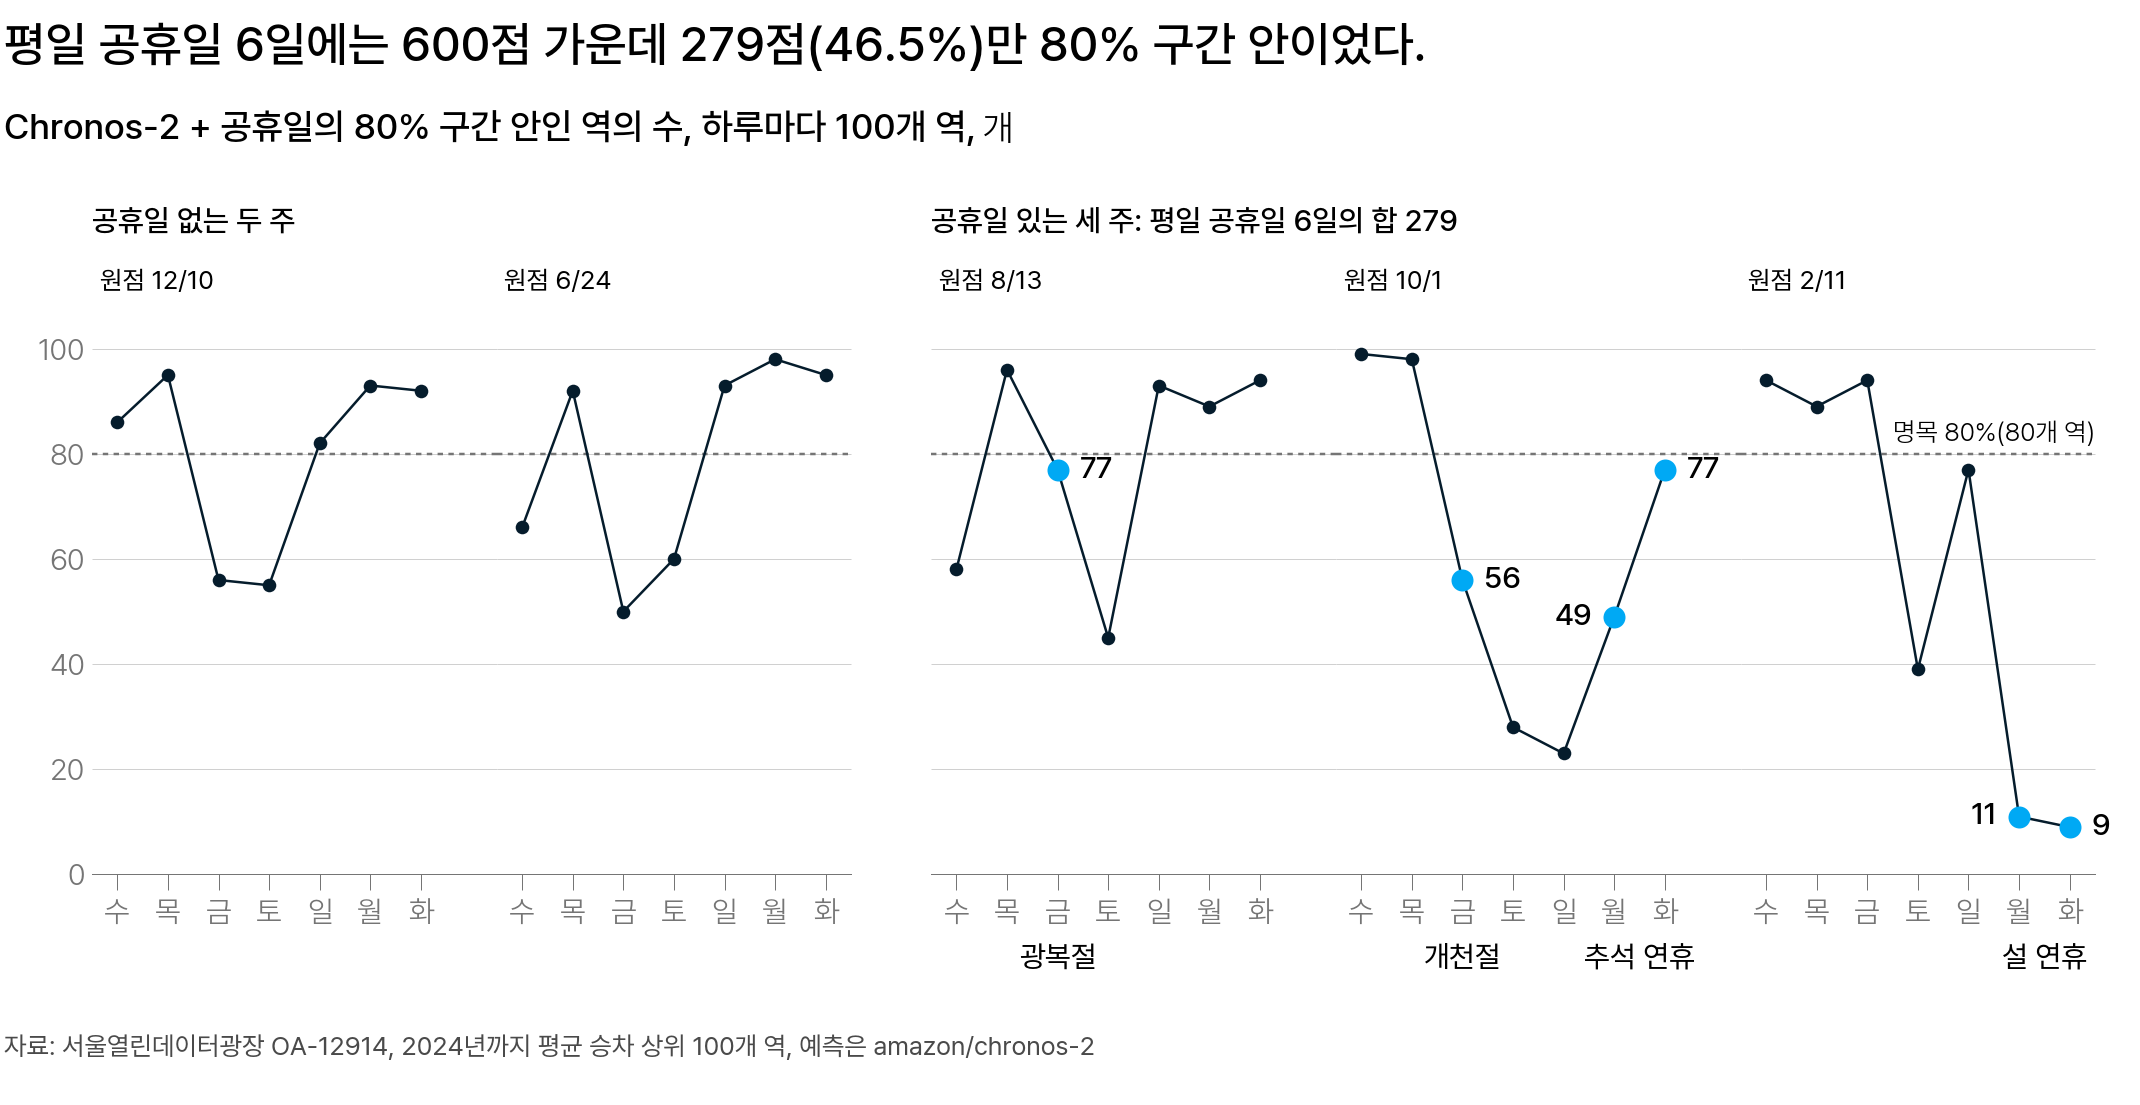

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 하늘색 여섯 점이 평일 공휴일 당일이고, 설 연휴 이틀은 100개 역 가운데 11개 · 9개 역만 구간 안이었다. 왼쪽 두 주에서 금 · 토의 낮은 네 점은 실제 승차가 위 끝보다 많은 역이 몰린 날이다</em></p>

가게 예시의 구간은 휴일에도 80～120명 그대로였습니다. 반면 Chronos-2 + 공휴일의 구간은 강남역 설날처럼 평일 공휴일에 낮게 나왔습니다.

그런데도 당일의 구간 밖 600 − 279 = 321점 가운데 254점은 실제 승차가 아래 끝보다 적었습니다.

한편 당일을 뺀 날의 74.4% 도 명목 80% 보다 낮습니다. 평일 공휴일과 이어진 주말에 구간 안인 역이 절반에 못 미친 날이 있었기 때문입니다.

당일은 구간 밖인 점이 절반을 넘으므로, 인력은 당일과 나머지 날을 나눠서 정합니다.

> 평일 공휴일 당일 인력은 구간으로 정하지 않고, 나머지 날에는 포함률 74.4% 를 함께 전달합니다.

<details class="lms-extra"><summary>자세히 — 구간 밖 점이 벗어난 쪽과 위 끝만큼 둔 인력</summary>

공휴일 있는 세 주의 구간 밖 705점은 아래 끝보다 적은 점이 더 많습니다(단위: 점).

| 공휴일 있는 세 주의 날 | 아래 끝보다 적은 점 | 위 끝보다 많은 점 |
|---|---:|---:|
| 세 주 전체 | 524 | 181 |
| 평일 공휴일 당일 | 254 | 67 |
| 평일 공휴일 당일을 뺀 날 | 270 | 114 |

셋째 행은 첫 행에서 둘째 행을 뺀 값입니다. 아래 끝보다 적은 점은 524 − 254 = 270점이고, 위 끝보다 많은 점은 181 − 67 = 114점입니다.

평일 공휴일 당일을 뺀 날에도 아래로 벗어난 점이 더 많아, 위 끝만큼 두면 인력이 남는 날이 더 많습니다.

강남역 2월 17일에 위 끝인 45,911명분 인력을 두었다면, 실제 14,973명보다 30,938명분이 남습니다.

</details>

**그러면 당일 인력은 무엇으로 정할까요?** 설 연휴 평일 이틀은 설 연휴 보정을 배울 때 정한 점 예측으로 정합니다. 1주 전 같은 요일 승차에 지난해 같은 날의 비를 곱한 값입니다.

| 강남역의 날 | 점 예측 | 실제 승차 |
|---|---:|---:|
| 2월 16일(월) 설날 전날 | 91,553 × 0.218 ≈ 19,959명 | 21,453명 |
| 2월 17일(화) 설날 | 95,750 × 0.142 ≈ 13,597명 | 14,973명 |

이 점 예측을 쓰는 까닭은 설 연휴에는 공휴일 열을 입력한 예측도 실제보다 높았기 때문입니다.

나머지 4일은 광복절 · 개천절 · 추석 연휴 이틀입니다. 이 4일의 인력은 어느 분위수 열에 맞출지와 함께 임계비율을 배울 때 정합니다.

<div class="lms-summary">

**정리**

Chronos-2 + 공휴일 구간의 포함률은 공휴일 없는 두 주에 79.5% 로 명목 80% 에 가까웠습니다. 공휴일 있는 세 주에는 구간이 1.52배로 길어지고도 66.4% 였습니다.

**할 일**

- 원점마다 `((fc["y"] >= fc["0.1"]) & (fc["y"] <= fc["0.9"])).mean()` 으로 포함률을 구하고, 평균 구간 길이와 함께 봅니다

평일 공휴일이 있는 주의 구간도 제로샷 구간보다 포함률이 높으므로, 버리지 않고 포함률과 함께 전달합니다.

</div>

> **[문제] 공휴일 유무로 나눈 포함률로 쓰는 인력 계획표 문장**
>
> Chronos-2 + 공휴일 80% 구간의 포함률은 공휴일 없는 두 주 79.5%, 공휴일 있는 세 주 66.4%, 원점 5개 평균 71.7% 였습니다. 다음 주 역별 인력 계획을 받는 운영팀에 이 구간을 전달할 때 함께 적을 문장을 두 문장으로 써 보세요.

## 4. 정리와 팀 라운드

공휴일 열을 입력한 Chronos-2 의 80% 구간을 다음 주 역별 인력 계획에 그대로 써도 될까요?

공휴일 없는 주에는 그대로 씁니다. 평일 공휴일이 있는 주에는 그대로 쓰지 않고, 포함률을 함께 전달합니다.

### 80% 구간을 전달하기 전에 확인할 다섯 가지 [필수]

80% 구간을 운영팀에 전달하기 전에 다섯 가지를 차례로 확인합니다.

**질문 1. 구간을 정한 뒤에 온 날로 포함률을 계산했는가?** 구간을 정할 때 쓴 날로 계산하면 명목 80% 에 가깝게 나올 수밖에 없습니다.

**질문 2. 포함률을 명목 80% 와 비교했는가?** 평균 MASE 의 차이에 쓴 시드 범위 0.077 은 포함률 비교에는 쓰지 않습니다.

**질문 3. 구간 길이를 같은 점끼리 비교했는가?** 포함률은 구간을 넓히기만 해도 오르고, 구간 길이는 역마다 다르기 때문입니다.

**질문 4. 공휴일이 있는 주와 없는 주, 평일 공휴일 당일을 나눴는가?** 평균 하나로는 포함률이 낮은 날이 드러나지 않습니다.

**질문 5. 구간 밖 점이 위와 아래 가운데 어느 쪽으로 벗어났는가?** 포함률이 같아도 위로 벗어난 점이 많으면 인력이 모자란 날이 늘어납니다.

### 결론: 80% 구간은 포함률과 함께 전달한다 [필수]

역과 날마다 80% 구간의 두 끝, 그날의 구간 길이, 그날에 맞는 포함률을 함께 전달합니다. 주간 인력 계획표에 적는 값은 상황에 따라 셋으로 나뉩니다.

| 상황 | 계획표에 적는 값 | 강남역의 예 |
|---|---|---|
| 공휴일 없는 주 | 두 끝과 구간 길이, 포함률 79.5%, 위 끝보다 많은 점 18.9%(금 · 토에 몰림) | 6월 26일(금) 93,593～99,793명, 길이 6,200명 |
| 평일 공휴일이 있는 주의 당일을 뺀 날 | 두 끝과 구간 길이, 당일을 뺀 날의 포함률 74.4% | 2월 12일(목) 88,339～98,148명, 길이 9,809명 |
| 평일 공휴일 당일 | 「당일 인력은 구간으로 정하지 않는다」와 따로 정한 값 | 2월 17일(화) 설날, 점 예측 13,597명 |

여기서는 인력을 위 끝(0.9 열)에 맞춘다고 가정합니다. 그러면 구간 길이는 승차가 아래 끝만큼일 때 남는 인력입니다. 어느 열에 맞출지는 임계비율을 배울 때 비용으로 정합니다.

구간 길이는 평균 대신 그 역의 값을 적습니다. 강남역 6,200명은 공휴일 없는 두 주 평균 2,839명의 2.2배이기 때문입니다.

**평가표에 추가하는 값**

평가표에는 두 Chronos-2 모델의 80% 포함률과 평균 구간 길이를 공휴일 유무로 나눠 추가합니다.

| 평가표의 열 | Chronos-2 제로샷 | Chronos-2 + 공휴일 | 비교 기준 |
|---|---:|---:|---|
| 평균 MASE | 1.766 | 0.742 | 시드 범위 0.077 |
| 80% 포함률, 공휴일 없는 두 주 | 85.1% | 79.5% | 명목 80% |
| 80% 포함률, 공휴일 있는 세 주 | 41.6% | 66.4% | 명목 80% |
| 평균 구간 길이, 공휴일 없는 두 주 | 3,082명 | 2,839명 | 같은 주의 다른 모델 |
| 평균 구간 길이, 공휴일 있는 세 주 | 3,768명 | 5,734명 | 같은 주의 다른 모델 |

평가표에는 계획표의 74.4% 대신 세 주 전체의 포함률 66.4% 를 적습니다. 두 모델을 같은 2,100점으로 비교하기 때문입니다.

가장 중요한 원칙은 하나입니다.

> 구간을 얼마나 믿을지는 명목 80% 보다, 조건이 다른 날을 나눠 구한 포함률로 정합니다.

<details class="lms-extra"><summary>자세히 — 일곱 방식의 평가표</summary>

앞의 MASE 세 열은 공변량을 배울 때까지의 평가표 값 그대로입니다. 직전 7일 평균은 원점 전 7일 승차의 평균을 다음 7일의 예측값으로 쓰는 방식입니다.

<div class="lms-wide">

| 방식 | 평균 MASE | MASE(공휴일 없는 두 주) | MASE(공휴일 있는 세 주) | 80% 포함률(공휴일 없는 두 주) | 80% 포함률(공휴일 있는 세 주) | 평균 구간 길이(공휴일 없는 두 주) | 평균 구간 길이(공휴일 있는 세 주) |
|---|---:|---:|---:|---:|---:|---:|---:|
| 계절 나이브 | 1.838 | 0.445 | 2.767 | 없음 | 없음 | 없음 | 없음 |
| 직전 7일 평균 | 2.984 | 1.935 | 3.684 | 없음 | 없음 | 없음 | 없음 |
| 글로벌 MLP(MSE 손실) | 1.848 | 0.739 | 2.587 | 없음 | 없음 | 없음 | 없음 |
| 글로벌 MLP(MAE 손실) | 1.774 | 0.359 | 2.717 | 없음 | 없음 | 없음 | 없음 |
| Chronos-2 제로샷 | 1.766 | 0.271 | 2.763 | 85.1% | 41.6% | 3,082명 | 3,768명 |
| Chronos-2 + 공휴일 | 0.742 | 0.322 | 1.022 | 79.5% | 66.4% | 2,839명 | 5,734명 |
| [참고] 글로벌 MLP(MAE 손실) + 공휴일 | 0.682 | 0.344 | 0.908 | 없음 | 없음 | 없음 | 없음 |

</div>

제로샷의 공휴일 없는 두 주 포함률 85.1% 는 1,192 ÷ 1,400 입니다.

Chronos-2 가 아닌 다섯 방식은 이 평가표에서 구간을 만들지 않아 「없음」으로 표시했습니다.

[참고] 모델은 공변량을 배울 때 평가표에 [참고] 로 표시한 MLP 입니다. 공휴일 열과 함께 시드 0 으로 한 번 학습했습니다. 이 평가표에서는 구간을 만들지 않았으므로, 구간이 필요한 인력 계획에는 Chronos-2 + 공휴일을 씁니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 원점별 값과 다음 주가 지난 뒤의 재계산</summary>

평가표의 포함률과 평균 구간 길이를 원점별로 나눈 표입니다.

| 예측 원점 | 채점한 주 | 제로샷 포함률 | Chronos-2 + 공휴일 포함률 | 제로샷 평균 구간 길이 | Chronos-2 + 공휴일 평균 구간 길이 |
|---|---|---:|---:|---:|---:|
| 2025-08-13 | 공휴일 있는 주 | 70.6% | 78.9% | 4,017명 | 4,525명 |
| 2025-10-01 | 공휴일 있는 주 | 23.9% | 61.4% | 4,573명 | 7,476명 |
| 2025-12-10 | 공휴일 없는 주 | 82.3% | 79.9% | 2,701명 | 2,760명 |
| 2026-02-11 | 공휴일 있는 주 | 30.3% | 59.0% | 2,714명 | 5,202명 |
| 2026-06-24 | 공휴일 없는 주 | 88.0% | 79.1% | 3,462명 | 2,918명 |

공휴일 없는 두 주와 공휴일 있는 세 주의 값은 원점별 값의 평균입니다. 원점마다 700점이라 점을 모두 합쳐 구한 값과 같습니다.

Chronos-2 + 공휴일의 공휴일 있는 세 주는 원점별 값의 평균으로 (78.9 + 61.4 + 59.0) ÷ 3 = 66.4% 입니다.

구간 안 점을 합쳐 계산해도 (552 + 430 + 413) ÷ 2,100 = 66.4% 로 같습니다.

빠진 날이 있어 원점마다 점의 수가 다르면 두 값이 달라지므로, 어느 방법으로 구했는지 함께 적습니다.

주간 인력 계획표를 보낸 주가 지나면, 그 주의 700점으로 같은 계산을 해 위 원점별 표에 한 행을 더합니다. 공휴일 없는 주는 12월과 6월의 두 주뿐이라, 주가 늘수록 포함률도 위 끝보다 많은 점의 비율도 더 믿을 만한 값이 됩니다.

<img src="https://otexts.com/fpp3/toolbox_files/figure-html/cv1-1.png" alt="예측 원점을 하나씩 옮기며 채점하는 그림" width="640" height="300"/>
<p align="center"><em>▲ 예측 원점을 하나씩 옮기며 채점하는 그림. 가로축의 time 은 시간이다. 한 행이 원점 하나이고, 파란 점까지의 값으로 예측해 주황 점에서 채점한다. 원점을 더할수록 채점한 날이 늘어난다 (출처: Hyndman &amp; Athanasopoulos, Forecasting: Principles and Practice 3rd ed.)</em></p>

공휴일 없는 주의 포함률이 여러 주 이어서 한 주 700점의 우연한 변동 범위 77.0～83.0% 아래로 내려가면, 구간을 그대로 쓰던 기준을 다시 검토합니다.

</details>

<div class="lms-summary">

**정리**

공휴일 없는 주에는 80% 구간을 그대로 쓰고, 위 끝보다 많은 점 18.9% 를 함께 전달합니다. 평일 공휴일이 있는 주에는 당일을 뺀 날의 포함률 74.4% 와 그 역의 구간 길이를 함께 전달하고, 당일 인력은 구간으로 정하지 않습니다.

**할 일**

- 다음 주 7일에 평일 공휴일이 있는지 달력으로 먼저 확인합니다

공휴일 열을 입력한 Chronos-2 의 80% 구간은 공휴일 없는 주에만 그대로 씁니다.

</div>

### 팀 라운드: 평일 공휴일이 있는 주의 80% 구간 [필수]

**아래 질문의 답은 수업에서 팀이 함께 정합니다.** 지금은 자기 답과 근거만 적어 두면 됩니다. 해설은 수업 뒤에 열립니다.

각자 답과 확신도(1～5)를 적어 잠그면 팀의 답 분포가 공개됩니다. 근거 세 문장을 나눠 토론한 뒤 팀이 답 하나로 모아 제출합니다.

> **[문제] 팀 라운드: 평일 공휴일이 있는 주의 계획표에 80% 구간을 어떻게 전달할까**
>
> 다음 주는 평일 공휴일이 있는 주입니다. 역 운영팀은 100개 역의 7일 계획표를 받아 날마다 인력의 범위를 정합니다. 운영팀은 구간과 함께 그 구간을 얼마나 믿어도 되는지 적어 달라고 합니다. 공휴일 있는 세 주에서 Chronos-2 + 공휴일의 80% 구간을 채점한 결과는 이렇습니다.
> 
> - **세 주 전체 21일** 2,100점 가운데 1,395점이 구간 안, 포함률 66.4%
> - **평일 공휴일 당일 6일** 600점 가운데 279점, 46.5%
> - **당일을 뺀 평일 9일** 900점 가운데 811점, 90.1%
> - **주말 6일** 600점 가운데 305점, 50.8%. 날마다 구간 안인 역은 토 45 · 일 93 · 토 28 · 일 23 · 토 39 · 일 77개. 23개인 일요일은 추석 연휴와 겹친 날입니다
> 
> 당일을 뺀 15일을 합치면 1,500점 가운데 1,116점, 74.4% 입니다. 세 주의 평균 구간 길이는 5,734명으로 제로샷 3,768명의 1.52배입니다.
> 
> 팀 안에서 의견이 셋으로 나뉘었습니다.
> 
> - **관점 A: 7일 모두 구간을 전달하고 포함률 66.4% 를 함께 적는다.** 공휴일 열을 입력해 포함률이 제로샷의 41.6% 에서 66.4% 로 높아졌다. 수가 하나라 운영팀이 계획표를 보기 쉽다.
> - **관점 B: 당일 인력만 따로 정하고, 나머지 날은 구간과 포함률 74.4% 를 함께 전달한다.** 당일은 600점 가운데 절반 넘게 구간 밖이었다. 나머지 날은 15일을 합쳐 계산해, 며칠의 결과에 좌우되지 않는다.
> - **관점 C: 당일과 주말 인력을 따로 정하고, 구간은 당일을 뺀 평일에만 쓴다.** 74.4% 는 평일 90.1% 와 주말 50.8% 를 합친 값이다. 주말 6일 가운데 4일은 구간 안인 역이 절반에 못 미쳤다.
> 
> 자기 입장 하나와 근거 세 문장, 다음에 확인할 일 하나, 그리고 확신도를 정해 오세요.